<div style="background:#0EA5A4;color:#FFFFFF;padding:34px 36px;border-radius:18px;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;">
<span style="background:#FF6B5A;color:#FFFFFF;padding:4px 16px;border-radius:999px;font-weight:bold;">컴퓨팅사고 · 12주차</span>
<div style="font-size:2.3em;font-weight:bold;margin-top:14px;">인공지능 라이브러리로 문서 분류 응용 만들기</div>
<div style="font-size:1.25em;margin-top:6px;">AI 프로젝트 개관 &nbsp;·&nbsp; 모델은 어떻게 배우고 답하나 &nbsp;·&nbsp; 라이브러리 가져다 쓰기 &nbsp;·&nbsp; RNN 으로 뉴스 제목 분류</div>
<div style="margin-top:18px;opacity:0.9;">연세대학교 미래캠퍼스 · RC융합대학 교양기초 &nbsp;|&nbsp; 실습 노트북 — 수업 사이트(JupyterLite)에서 엽니다</div>
</div>

# 12주차 학습 안내

지난주까지 우리는 **사람이 규칙을 쓰는** 프로그램을 만들었습니다. 점수가 90 이상이면 A, 파일이 없으면 안내문. 오늘부터 수업이 두 가지로 바뀝니다. 하나는 **AI 프로젝트**입니다. 남은 수업에서는 팀이 **스스로 문제를 정하고 AI 와 함께** 프로그램을 만듭니다. 1교시에 그 프로젝트가 무엇이고 어떻게 진행되는지 봅니다. 또 하나는 **인공지능 모델**입니다. “이 뉴스 제목은 스포츠 기사인가?” 같은 문제는 규칙을 쓰기가 어렵습니다. 단어가 너무 많고 예외도 너무 많습니다. 2교시에 **규칙을 쓰는 대신 데이터에서 배우게 하는** 방법을 배우고, 3교시에 남이 만들어 둔 **인공지능 라이브러리**를 가져다 뉴스 제목 분류기를 직접 만듭니다.

| 교시 | 주제 | 만드는 것 |
|:---:|:---|:---|
| **1교시** | **AI 프로젝트 개관** — 왜 프로젝트인가 &nbsp;·&nbsp; 프로젝트의 뼈대와 일정 &nbsp;·&nbsp; **불편을 문제로 다듬기** &nbsp;·&nbsp; 팀과 역할 &nbsp;·&nbsp; 팀 구성 설문 | 내 불편 3가지를 입력 · 출력이 있는 문제로 적어 보기 |
| **2교시** | **인공지능 모델이란** — 학습과 추론 &nbsp;·&nbsp; 문서를 숫자로 &nbsp;·&nbsp; **인공지능 라이브러리 지도**와 가져다 쓰는 법 | 숫자 한 개짜리 모델을 손으로 학습시켜 보기 |
| **3교시** | **RNN 으로 뉴스 제목 분류기 만들기** — 데이터 → 전처리 → 모델 → 학습 → 평가 → 추론 | 뉴스 제목을 스포츠 · 경제 · 날씨 · 음식으로 나누는 프로그램 |

**오늘 수업을 마치면**

0. 남은 수업의 **AI 프로젝트**가 무엇인지 알고, 내 불편을 **입력 · 출력 · 범위**가 있는 문제로 다듬을 수 있습니다.
1. **모델 · 매개변수 · 학습 · 손실 · 에포크 · 추론 · 과적합**이 무슨 뜻인지 말로 설명할 수 있습니다.
2. 문서가 어떻게 **숫자의 열**로 바뀌어 모델에 들어가는지 압니다.
3. 인공지능 라이브러리가 어떤 것들이 있고, `import` 해서 **데이터 → 모델 → `fit` → `predict`** 순서로 쓴다는 공통 패턴을 압니다.
4. RNN 이 “단어를 한 개씩 읽으며 메모를 갱신하는 모델”임을 알고, 라이브러리로 문서 분류기를 학습시키고 새 문장을 분류할 수 있습니다.

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 이 노트북을 읽는 법</b><br>회색 코드 셀은 <b>직접 실행</b>하는 곳입니다. 실행하기 <b>전에 결과를 먼저 예상</b>해 보세요. 오늘은 셀을 <b>위에서부터 차례로</b> 실행해야 합니다. 뒤의 셀이 앞의 셀에서 만든 데이터와 모델을 쓰기 때문입니다.<br><b style='color:#FF6B5A;'>✏️ 실습</b> 상자가 나오면 직접 코드를 작성하고, 바로 아래 <b>🔍 자가 점검</b> 셀로 확인합니다. 정답 예시는 접혀 있습니다. <b>먼저 스스로 풀어 본 뒤</b> 여세요.<br>노트북 맨 끝에 <b style='color:#FF6B5A;'>📝 과제</b>가 있습니다.</div>

## 1-0. 시작 전에

**① 수업 사이트에서 열기** — 이 노트북은 LearnUs에 올린 **수업 사이트 링크**로 엽니다. 설치도 로그인도 필요 없습니다. 다른 곳(Google Colab 등)에서 열면 자가 점검 도구가 동작하지 않습니다.

**② 작업 내용은 이 브라우저에만 저장됩니다** — 다른 기기나 다른 브라우저에서는 보이지 않고, 브라우저 데이터를 지우면 사라집니다. 수업이 끝나면 메뉴에서 `File → Download` 로 파일을 내려받으세요. **파일이 내 손에 있어야 저장된 것입니다.** (PC: 다운로드 폴더, 아이패드: ‘파일’ 앱)

**③ 처음 상태로 되돌리기** — `File → Open…` 으로 파일 목록을 열어 이 노트북을 삭제한 뒤 새로고침하면 원본을 다시 받아 옵니다. 삭제 전에 ②로 내려받아 두세요.

**④ 아이패드** — Safari 일반 탭에서 여세요(사생활 보호 탭에서는 저장이 안 됩니다). 셀 실행은 툴바의 **▶** 버튼, 들여쓰기는 **스페이스 4칸**입니다.

In [ ]:
#@title ▶ 먼저 실행하세요 — 자가 점검 도구 준비
import importlib.util as _ilu

def _in_class_site():
    # 수업 사이트(JupyterLite)에서 열었는지 확인합니다. Google Colab 이면 False 입니다.
    return _ilu.find_spec("google") is None or _ilu.find_spec("google.colab") is None

if not _in_class_site():
    print("⚠️ 이 노트북은 Google Colab 용이 아닙니다.")
    print("   LearnUs 에 올린 수업 사이트 링크로 열어 주세요. 여기서는 자가 점검이 동작하지 않습니다.")
    raise SystemExit

def check(name, test):
    """실습 답을 확인하는 도구입니다. 수정하지 마세요."""
    if not _in_class_site():
        print(f"⚠️ {name}: 수업 사이트에서 실행해야 점검할 수 있습니다.")
        return
    try:
        ok = test()
    except NameError as e:
        print(f"⏳ {name}: 아직 필요한 변수가 없습니다 → {e}")
        return
    except Exception as e:
        print(f"❌ {name}: 확인 중 오류가 났습니다 → {type(e).__name__}: {e}")
        return
    if isinstance(ok, str):           # 아직 풀지 않은 상태 — test 가 안내 문구를 돌려준 경우
        print(f"⏳ {name}: {ok}")
        return
    print(f"✅ {name}: 통과!" if ok else f"❌ {name}: 값이 다릅니다. 다시 확인해 보세요.")

# 수업 사이트에서는 %%writefile 로 방금 만든 .py 파일을 import 가 바로 찾지 못합니다 (파일 목록 캐시).
# import 때마다 캐시를 비우는 작은 장치를 끼워 둡니다.
import importlib as _il, sys as _sys

class _RefreshFinder:
    _busy = False                     # invalidate_caches 가 안에서 다시 import 를 일으켜도 되돌아 들어오지 않게

    @classmethod
    def find_spec(cls, name, path=None, target=None):
        if not cls._busy:
            cls._busy = True
            try:
                _il.invalidate_caches()
            finally:
                cls._busy = False
        return None

if not any(type(f).__name__ == "_RefreshFinder" for f in _sys.meta_path):
    _sys.meta_path.insert(0, _RefreshFinder())

print("준비 완료! 이제 수업을 시작합니다.")

<div style="background:#0EA5A4;color:#FFFFFF;padding:20px 26px;border-radius:14px;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:3px 14px;border-radius:999px;font-weight:bold;">1교시</span>&nbsp;&nbsp;<span style="font-size:1.5em;font-weight:bold;">AI 프로젝트 개관 — 내 불편을 AI 와 함께 푸는 프로젝트</span><span style="float:right;opacity:0.9;">⏱ 약 50분</span><ul style="margin:10px 0 0 0;line-height:1.7;"><li><b>지금까지와 앞으로</b> — 따라 하는 수업에서 <b>스스로 정하는</b> 수업으로</li><li><b>AI 응용 프로젝트의 뼈대</b> — 불편 → 문제 → 데이터 · 도구 → 만들기 → 검증 → 발표, 그리고 남은 일정</li><li><b>문제 정의</b> — 불편을 입력 · 출력 · 범위가 있는 문제로 다듬는 4단계</li><li><b>팀</b> — 구성 원칙 · 매주 바뀌는 역할 · 팀 규칙</li><li><b>팀 구성 설문</b> — 지금 바로 응답 (약 7분)</li></ul></div>

## 1-1. 지금까지와 앞으로

4주차부터 11주차까지 우리는 Python 의 문법과 자료구조, 함수와 클래스, 알고리듬, 파일과 예외를 배웠습니다. 교수가 설명하고 여러분이 따라 하는 방식이었습니다. 이제 도구는 손에 들었습니다. 남은 수업에서는 **쓰는 쪽을 바꿉니다.**

| | 지금까지 | 앞으로 |
|:---|:---|:---|
| 문제 | 교수가 정한 문제 | **팀이 스스로 찾은** 내 생활의 불편 |
| 코드 | 노트북의 빈 셀을 채움 | **AI 와 함께** 처음부터 만듦 |
| 단위 | 혼자 | 3 ~ 4명 팀, 역할을 돌아가며 |
| 결과 | 자가 점검 ✅ | 돌아가는 프로그램 + 과정 기록 + 발표 |

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 왜 이렇게 하나</b><br>① 현장에서 프로그램을 만드는 방식이 이미 이렇습니다. 문제를 정하고, AI 에게 코드를 요청하고, 결과를 검증합니다.<br>② AI 가 코드를 써 주는 시대에 사람의 몫은 <b>어떤 문제를 풀 것인가</b>를 정하는 일과 <b>맞게 풀렸는가</b>를 확인하는 일입니다. 컴퓨팅 사고의 핵심인 <b>문제 정의 · 분해 · 입력과 출력</b>이 그대로 쓰입니다.<br>③ 지금까지 배운 문법은 AI 가 쓴 코드를 <b>읽고 고치고 설명하기</b> 위한 것이었습니다. 읽지 못하는 코드는 검증할 수 없습니다.</div>

## 1-2. AI 응용 프로젝트의 뼈대

어떤 AI 응용이든 만드는 순서는 비슷합니다. 여섯 단계입니다.

| 단계 | 할 일 | 묻는 질문 |
|:---:|:---|:---|
| ① 불편 찾기 | 일상 · 학교생활 · 전공에서 반복되는 귀찮은 일을 적는다 | 무엇이 매번 귀찮은가? |
| ② 문제로 다듬기 | 입력 · 출력 · 범위를 정한다 | 무엇을 넣으면 무엇이 나와야 해결인가? |
| ③ 데이터 · 도구 정하기 | 필요한 데이터가 어디 있는지, 어떤 라이브러리 · AI 를 쓸지 정한다 | 데이터는 어디서 구하나? |
| ④ 만들기 | AI 에게 요구사항을 전달해 코드를 만들고, 읽고, 고친다 | 이 코드가 무슨 일을 하는지 설명할 수 있나? |
| ⑤ 검증 | 여러 입력으로 돌려 보고 틀린 곳을 찾는다 | 어떤 입력에서 틀리나? |
| ⑥ 발표 · 기록 | 무엇을 왜 만들었고, 어디서 막혔는지 남긴다 | 다른 팀이 따라 만들 수 있나? |

오늘 2 · 3교시의 뉴스 제목 분류기가 이 뼈대의 **축소판**입니다. 문제(제목 → 주제), 데이터(제목 160개), 도구(`minirnn` 라이브러리), 검증(테스트셋 정확도)까지 한 번에 지나갑니다. 프로젝트에서는 이 여섯 단계를 **팀이 직접** 밟습니다.

**남은 일정** (수업계획서 기준)

| 주차 | 수업 | 프로젝트 |
|:---:|:---|:---|
| **12주** (오늘) | AI 프로젝트 개관 · 인공지능 모델과 라이브러리 | 팀 구성 설문 |
| **13주** | 언어모델이란 무엇인가 · AI 를 활용한 코딩과 디버깅 | 팀 발표, 문제 정의 |
| **14주** | AI 를 활용하여 챗봇 만들기 — UI 설계 · 외부 API | 만들기 · 검증 |
| **15주** | 자율학습 | AI 응용 과제물 제출 |
| **16주** | 기말고사 | |

<div style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#6B7280;">📎 세부 일정은 LearnUs 공지로</b><br>설문 마감 시각, 팀 발표일, 최종 산출물의 형식, 팀 점수와 동료 평가의 비율, 프로젝트에서 쓸 AI 도구와 사용 규칙은 <b>LearnUs 공지</b>로 알립니다. 이 노트북의 표는 큰 흐름만 보여 줍니다.</div>

## 1-3. 문제 정의 — 불편에서 프로그램으로

프로젝트의 성패는 대부분 **① → ②**, 곧 불편을 **풀 수 있는 문제**로 다듬는 데서 갈립니다. 팀에서는 다음 네 단계로 진행합니다. 순서가 중요합니다. **개인 → 팀** 순서로 가야 목소리 큰 한 사람의 생각으로 바로 정해지는 것을 막을 수 있습니다.

| 단계 | 방법 | 규칙 |
|:---:|:---|:---|
| 1. 개인 | 각자 겪는 불편 3가지를 적는다 (5 ~ 10분) | **대화 금지.** 설문에 적은 것을 써도 됩니다 |
| 2. 공유 | 한 사람씩 돌아가며 읽는다 | **평가 · 반박 없이 듣기만** |
| 3. 선택 | 비슷한 것을 묶고, 각자 2표씩 투표해 하나를 고른다 | 다수결보다 ‘우리가 만들 수 있는가’ |
| 4. 정의 | 고른 불편을 Python 과 AI 로 풀 수 있는 문제로 다듬는다 | 아래 세 질문에 답한다 |

다듬을 때 팀이 답할 **세 질문**입니다.

- **입력** — 프로그램에 무엇을 넣는가?
- **출력** — 무엇이 나오면 불편이 해결된 것인가?
- **범위** — 남은 수업 기간 안에 만들 수 있는 크기인가?

| 적어낸 불편 | 다듬은 문제 (입력 → 출력) |
|:---|:---|
| 시간표 짜기가 귀찮다 | 과목 목록을 넣으면 → 시간이 안 겹치는 조합을 찾아주는 프로그램 |
| 용돈이 어디로 새는지 모르겠다 | 지출 내역을 넣으면 → 항목별 합계와 그래프를 보여주는 프로그램 |
| 조별과제 일정 잡기가 힘들다 | 팀원별 가능한 시간을 넣으면 → 공통으로 비는 시간을 찾아주는 프로그램 |
| 25명을 조건에 맞게 8팀으로 나누기 어렵다 | 설문 응답 파일을 넣으면 → 조건을 만족하는 팀 배정표를 내는 프로그램 (교수가 이번 팀 배정에 실제로 쓰는 것) |

세 질문에 답하지 못하는 불편은 다른 후보로 바꿉니다. “불편” 말고 “궁금한 것”, “전공에서 반복되는 작업”까지 넓혀도 됩니다.

<div style="background:#FFF7E6;color:#1F2937;border-left:6px solid #F59E0B;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#B45309;">🤔 범위를 재는 감각</b><br>“시간표 짜기가 귀찮다”에서 과목이 30개라면 조합은 몇 개쯤일까요? 전부 따져 봐야 할까요, 아니면 조건을 먼저 걸어 줄여야 할까요? 10주차의 탐색을 떠올려 보세요. — <b>범위 질문</b>은 이렇게 ‘계산이 끝나는가’까지 묻는 것입니다.</div>

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">✏️ 실습 1-1</span>&nbsp; <b>내 불편 3가지를 입력 · 출력으로</b> <span style="color:#6B7280;font-weight:normal;">(약 6분)</span><br>혼자서(대화 없이) 내가 겪는 불편 <b>3가지</b>를 적고, 각각 <b>입력</b>과 <b>출력</b>을 한 줄씩 붙여 보세요. 딕셔너리 3개를 담은 리스트 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">my_problems</code> 를 만듭니다. 키는 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&quot;불편&quot;</code>, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&quot;입력&quot;</code>, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&quot;출력&quot;</code> 세 개입니다.<br>완벽할 필요 없습니다. 입력 · 출력이 떠오르지 않는 불편은 그 자체로 ‘아직 문제가 아니다’라는 신호입니다. 여기 적은 것을 1-5 설문의 ‘불편 3가지’ 칸에 그대로 쓰면 됩니다.</div>

In [ ]:
my_problems = [
    {"불편": "...", "입력": "...", "출력": "..."},
    {"불편": "...", "입력": "...", "출력": "..."},
    {"불편": "...", "입력": "...", "출력": "..."},
]

for p in my_problems:
    print(f"- {p['불편']}  |  입력: {p['입력']}  →  출력: {p['출력']}")

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("실습 1-1", lambda: (len(my_problems) >= 3 and all(len(p.get(k, "").strip()) >= 2 and "..." not in p.get(k, "") for p in my_problems for k in ("불편", "입력", "출력"))) or "세 개 모두 불편 · 입력 · 출력을 채워 주세요")

<details style="background:#FFFFFF;color:#1F2937;border:1px dashed #FF6B5A;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#FF6B5A;font-weight:bold;">💡 ✏️ 실습 1-1 정답 예시 — 내 불편 3가지를 입력 · 출력으로 (먼저 스스로 풀어 본 뒤 여세요)</summary><div style="margin-top:8px;"><pre style="background:#1F2937;color:#F9FAFB;padding:14px 16px;border-radius:10px;font-family:Consolas,monospace;line-height:1.5;white-space:pre-wrap;overflow-wrap:anywhere;box-sizing:border-box;max-width:100%;">my_problems = [
    {&quot;불편&quot;: &quot;시간표 짜기가 귀찮다&quot;, &quot;입력&quot;: &quot;듣고 싶은 과목 목록&quot;, &quot;출력&quot;: &quot;시간이 안 겹치는 조합&quot;},
    {&quot;불편&quot;: &quot;용돈이 어디로 새는지 모르겠다&quot;, &quot;입력&quot;: &quot;한 달 지출 내역&quot;, &quot;출력&quot;: &quot;항목별 합계와 그래프&quot;},
    {&quot;불편&quot;: &quot;조별과제 일정 잡기가 힘들다&quot;, &quot;입력&quot;: &quot;팀원별 가능한 시간&quot;, &quot;출력&quot;: &quot;공통으로 비는 시간&quot;},
]

for p in my_problems:
    print(f&quot;- {p[&#x27;불편&#x27;]}  |  입력: {p[&#x27;입력&#x27;]}  →  출력: {p[&#x27;출력&#x27;]}&quot;)</pre></div></details>

## 1-4. 팀 — 구성 · 역할 · 규칙

**팀은 교수가 배정합니다.** 친한 사람끼리 모이면 실력이 한쪽으로 몰리고 한 사람이 다 하게 되기 쉽습니다. 주제는 팀이 스스로 고르고, **팀 구성만** 교수가 정합니다. 인원은 **3명**이 기본이고 남는 인원만 4명 팀이 됩니다.

배정 기준은 다음 순서입니다. 1-5 의 설문이 이 기준의 재료입니다.

1. 팀 전원이 **같은 계열**이 되지 않게 — 다른 눈이 섞여야 불편도 해법도 다양해집니다.
2. 팀원끼리 **관심 주제**가 겹치게 — 같은 쪽을 보는 사람이 모여야 문제를 빨리 고릅니다.
3. **코딩 자신감**의 평균이 팀마다 비슷하게.
4. **AI 사용 경험**이 팀마다 비슷하게.

**역할은 매주 바뀝니다.** 한 사람이 코딩을 다 하는 팀은 그 사람만 배웁니다.

| 역할 | 하는 일 |
|:---|:---|
| 문제 정의자 | 누구의 어떤 불편인지, 입력 · 출력을 정리한다 |
| 프롬프터 | AI 에게 요구사항을 전달하고 코드를 받아 온다 |
| 검증자 | 받은 코드를 여러 입력으로 돌려 보고 AI 의 오류를 찾는다 |
| 기록 · 발표자 (4명 팀) | 과정과 시행착오를 기록하고 발표를 준비한다 |

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 팀이 첫 모임에서 할 세 가지</b><br>① <b>팀 규칙 한 장</b> — 연락 방법, 역할 순서, 불참 시 처리를 팀이 직접 정해 제출합니다.<br>② 문제 정의 4단계(1-3)를 밟아 <b>후보 하나</b>를 고릅니다.<br>③ 발표 뒤 다른 팀의 질문에 답할 준비를 합니다. “그게 정말 문제인가?”, “데이터는 어디서 구하나?”<br>팀 점수에는 <b>동료 평가(개인 기여도)</b>가 반영됩니다. 비율은 LearnUs 공지로 알립니다.</div><div style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#6B7280;">📎 프로젝트에서 AI 는 적극 쓰되</b><br>프롬프터 역할이 있는 것처럼, 프로젝트에서 AI 로 코드를 만드는 것은 <b>권장</b>입니다. 조건은 하나입니다. 팀원 누구든 그 코드가 <b>무슨 일을 하는지 설명</b>할 수 있어야 합니다. 설명하지 못하는 코드는 검증자가 되돌려 보냅니다. 쓸 AI 도구와 세부 규칙은 13주차에 안내합니다.</div>

## 1-5. 팀 구성 설문 — 지금 바로 (약 7분)

아래 QR 코드를 휴대폰으로 찍거나 링크를 열어 응답해 주세요. 문항은 7개, 3분이면 됩니다.

<div style="text-align:center;margin:10px 0;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;">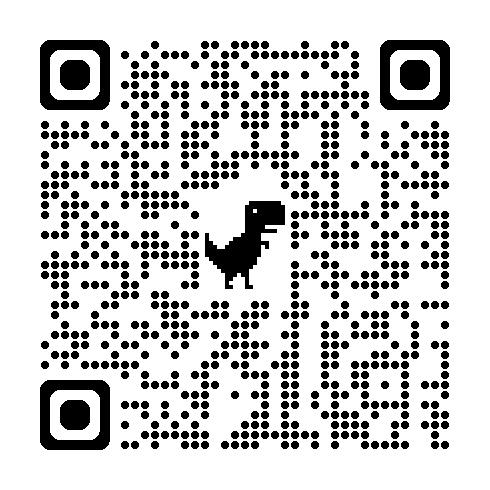<div style="color:#6B7280;font-size:0.9em;margin-top:4px;">AI 프로젝트 팀 구성을 위한 설문 — <a href='https://docs.google.com/forms/d/e/1FAIpQLSdkWwcl8fd3CXKDMxpDiFFrhfIAVfgELzQmh6QaRddiAzkS9A/viewform' target='_blank' style='color:#0B7C7B;'>링크로 열기</a></div></div>

| 문항 | 어떻게 답하나 |
|:---|:---|
| 학번 · 이름 | 학번은 숫자만. 같은 학번은 **마지막 응답**만 반영됩니다 |
| 계열 | 인문 / 사회 · 경영 / 이공 / 보건의료. 전공 미정이면 **앞으로 신청할 제1전공** 기준 |
| 코딩 자신감 | 1(혼자서는 어렵다) ~ 5(혼자서 짤 수 있다). 솔직하게 |
| AI 사용 경험 | 거의 안 씀 / 가끔 씀 / 매일 씀 |
| 관심 주제 | 학교생활 · 돈과 소비 · 건강과 운동 · 취미와 여가 · 전공 공부 · 사회와 환경 중 **정확히 2개** |
| 불편 3가지 | 실습 1-1 에 적은 것을 그대로. 배정에는 쓰지 않고 팀 논의의 재료가 됩니다 |

<div style="background:#FFF0EE;color:#1F2937;border-left:6px solid #FF6B5A;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#FF6B5A;">⚠️ 설문 응답은 팀 배정에만 씁니다</b><br>코딩 자신감 점수는 <b>공개하지 않으며</b> 성적과 무관합니다. 답을 고치고 싶으면 <b>다시 제출</b>하면 됩니다(마지막 응답 반영). 마감 시각은 LearnUs 공지에 있습니다. 마감 뒤 응답하지 않은 사람은 연락을 드립니다.</div><details style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#6B7280;font-weight:bold;">📎 교수가 팀을 어떻게 나누나 — 이것도 프로그램입니다</summary><div style="margin-top:8px;">설문 응답 파일(CSV)을 읽어, 25명을 무작위로 8팀으로 나눈 뒤 <b>두 사람을 맞바꿔 보고 기준 점수가 나아지면 바꾸는 일</b>을 수백 번 반복합니다. 10주차에 본 탐색과 같은 생각입니다. 입력은 설문 CSV, 출력은 팀 배정표. 기준은 위의 네 가지를 점수로 만든 것입니다. 1-3 표의 마지막 줄이 바로 이 문제입니다. 불편 → 입력 · 출력 → 코드로 가는 길을 교수도 똑같이 걸었습니다.</div></details>

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 1교시 정리</b><br>① 남은 수업은 <b>팀이 스스로 정한 문제</b>를 <b>AI 와 함께</b> 푸는 프로젝트입니다. 사람의 몫은 <b>문제 정의</b>와 <b>검증</b>입니다.<br>② AI 응용의 뼈대는 <b>불편 → 문제(입력 · 출력 · 범위) → 데이터 · 도구 → 만들기 → 검증 → 발표</b>. 오늘 2 · 3교시가 그 축소판입니다.<br>③ 문제 정의는 <b>개인 → 공유 → 선택 → 정의</b> 순서로. 세 질문(입력 · 출력 · 범위)에 답하지 못하면 아직 문제가 아닙니다.<br>④ 팀은 교수가 <b>계열은 다르게, 관심은 겹치게</b> 배정합니다. 역할은 매주 바뀌고, 팀 점수에 동료 평가가 반영됩니다.<br>⑤ <b>설문</b>에 지금 응답하세요. 마감과 세부 일정은 LearnUs 공지.</div>

<div style="text-align:center;color:#6B7280;">☕ 쉬는 시간 — 10분</div>

<div style="background:#0EA5A4;color:#FFFFFF;padding:20px 26px;border-radius:14px;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:3px 14px;border-radius:999px;font-weight:bold;">2교시</span>&nbsp;&nbsp;<span style="font-size:1.5em;font-weight:bold;">인공지능 모델이란 — 규칙을 쓰는 대신 데이터에서 배운다</span><span style="float:right;opacity:0.9;">⏱ 약 50분</span><ul style="margin:10px 0 0 0;line-height:1.7;"><li><b>규칙 쓰기 vs 배우기</b> — 왜 스팸 판별 규칙은 자꾸 깨지는가</li><li><b>학습과 추론</b> — 모델 · 매개변수 · 손실 · 에포크 · 과적합을 한 번에</li><li>숫자 한 개짜리 모델을 <b>직접 학습</b>시켜 손실이 줄어드는 것을 보기</li><li><b>문서를 숫자로</b> — 토큰화 · 어휘 사전 · 번호 열</li><li><b>인공지능 라이브러리 지도</b> — 어떤 것이 있고, 어떻게 가져다 쓰나</li></ul></div>

## 2-1. 규칙 쓰기 vs 배우기

지금까지 만든 프로그램은 모두 **사람이 규칙을 적은** 것입니다. 문자 메시지가 스팸인지 가리는 프로그램을 그 방식으로 만들어 봅시다. “당첨”이나 “무료”가 들어 있으면 스팸이라고 하겠습니다.

**예상해 보기** — 네 문장 가운데 몇 개를 맞힐까요? 틀리는 문장은 왜 틀릴까요?

In [ ]:
def is_spam(text):
    for word in ["당첨", "무료", "클릭"]:
        if word in text:
            return True
    return False

messages = [
    ("축하합니다 1등 당첨 지금 클릭", True),
    ("내일 수업 10시로 바뀌었어", False),
    ("무료 쿠폰 받아 가세요", True),
    ("오늘 학식 무료 시식 행사래 같이 갈래?", False),   # 친구가 보낸 평범한 문자인데…
]
for text, answer in messages:
    print(is_spam(text) == answer, "|", text)

마지막 문장이 틀립니다. “무료”가 있지만 스팸이 아닙니다. 그러면 “무료 시식”은 빼라는 규칙을 더합니다. 그러면 또 다른 예외가 나옵니다. 스팸 발송자가 “무료”를 “무.료”로 바꾸면 규칙이 또 깨집니다. **규칙은 사람이 미리 생각해 낸 경우만 다룹니다.** 경우가 수만 가지면 사람이 다 쓸 수 없습니다.

그래서 방향을 바꿉니다. 규칙을 쓰지 않고, **스팸 1,000통과 정상 문자 1,000통을 보여 주고 컴퓨터가 스스로 기준을 찾게** 합니다. 이것이 **기계 학습(machine learning)** 이고, 그렇게 찾은 기준을 담은 것이 **모델(model)** 입니다.

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 모델이란</b><br>모델은 <b>입력을 받아 출력을 돌려주는 함수</b>입니다. 7주차의 함수와 같습니다. 다른 점은 하나뿐입니다. 함수 안의 규칙(숫자들)을 <b>사람이 적지 않고 데이터로 정합니다.</b> 그 숫자들을 <b>매개변수(parameter)</b> 또는 <b>가중치(weight)</b> 라고 부릅니다. 오늘 만들 RNN 모델에는 매개변수가 약 2만 개 있고, 챗GPT 같은 거대 언어 모델에는 수천억 개가 있습니다. 개수가 다를 뿐 ‘데이터로 정한 숫자들’이라는 점은 같습니다.</div>

## 2-2. 학습과 추론 — 용어를 한 번에

모델을 쓰는 일은 두 단계로 나뉩니다. 먼저 데이터로 매개변수를 맞춰 가는 **학습(training)**, 그다음 다 배운 모델에 새 입력을 넣어 답을 받는 **추론(inference)** 입니다.

<div style="text-align:center;margin:10px 0;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;">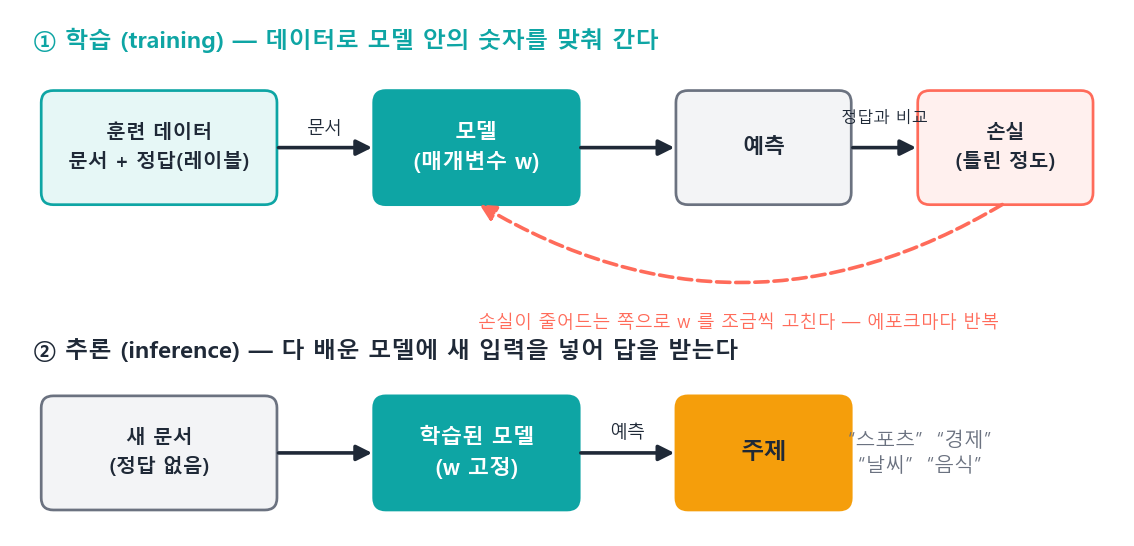<div style="color:#6B7280;font-size:0.9em;margin-top:4px;">학습은 ‘틀린 정도’를 보고 매개변수를 고치는 반복이고, 추론은 고친 매개변수를 그대로 쓰는 한 번의 계산입니다.</div></div>

시험공부에 빗대면 이렇습니다.

| 용어 | 뜻 | 시험공부로 말하면 |
|:---|:---|:---|
| **데이터셋**(dataset) | 입력과 정답(**레이블**, label)의 묶음 | 문제집 — 문제와 해답 |
| **훈련셋 / 테스트셋**(train / test set) | 학습에 쓰는 데이터 / 실력을 재려고 **따로 떼어 둔** 데이터 | 공부용 문제집 / 모의고사 |
| **모델**(model) | 입력 → 출력 함수. 안에 매개변수가 있다 | 학생의 머릿속 |
| **매개변수**(parameter) | 학습으로 정해지는 숫자들 | 머릿속에 자리 잡은 지식 |
| **예측**(prediction) | 모델이 내놓은 답 | 학생이 쓴 답 |
| **손실**(loss) | 예측이 정답과 **얼마나 다른지**를 재는 숫자. 작을수록 좋다 | 틀린 문제 수 |
| **학습**(training) | 손실이 줄어드는 쪽으로 매개변수를 **조금씩** 고치는 반복 | 틀린 문제를 보고 고쳐 가는 공부 |
| **에포크**(epoch) | 훈련셋 전체를 한 바퀴 도는 것 | 문제집을 처음부터 끝까지 한 번 푸는 것 |
| **추론**(inference) | 학습이 끝난 모델에 새 입력을 넣어 답을 받는 것 | 실제 시험 |
| **정확도**(accuracy) | 맞힌 개수 ÷ 전체 개수 | 점수 |
| **과적합**(overfitting) | 훈련셋은 다 맞히는데 새 데이터는 못 맞히는 상태 | 문제집 답을 **외워** 버린 학생 |

<div style="background:#FFF7E6;color:#1F2937;border-left:6px solid #F59E0B;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#B45309;">🤔 생각해 보기</b><br>① 공부용 문제집으로 시험을 보면 점수가 높게 나옵니다. 그 점수를 믿을 수 있을까요? 그래서 테스트셋은 왜 <b>따로</b> 떼어 두어야 할까요?<br>② 문제집을 100바퀴 돌면(에포크 100) 항상 더 잘하게 될까요? 어떤 일이 생길 수 있을까요?</div>

## 2-3. 학습을 눈으로 보기 — 숫자 한 개짜리 모델

말로만 들으면 추상적이니 **가장 작은 모델**을 직접 학습시켜 봅시다. 매개변수가 `w` 한 개뿐인 모델입니다.

> 예측 = `w` × 입력

어떤 비밀 규칙으로 만든 데이터 네 쌍이 있습니다. `(1, 2.5)`, `(2, 5.0)`, `(3, 7.5)`, `(4, 10.0)`. 사람은 한눈에 `w = 2.5` 임을 압니다. 컴퓨터는 모릅니다. `w = 0` 에서 출발해 **틀린 만큼 조금씩** 고치게 합니다.

```
for 에포크:
    for (x, y) in 데이터:
        예측 = w * x
        오차 = 예측 - y            # 양수면 너무 크게, 음수면 너무 작게 예측한 것
        w = w - 학습률 * 오차 * x   # 오차가 줄어드는 쪽으로 조금 움직인다
```

**예상해 보기** — `w` 는 에포크가 지날수록 어떻게 변할까요? 손실은요?

In [ ]:
data = [(1, 2.5), (2, 5.0), (3, 7.5), (4, 10.0)]    # (입력, 정답)
w = 0.0                 # 매개변수 — 아무것도 모르는 상태에서 출발
lr = 0.02               # 학습률(learning rate) — 한 번에 얼마나 고칠지

for epoch in range(1, 11):
    total_loss = 0
    for x, y in data:
        pred = w * x                    # 예측
        error = pred - y                # 오차
        w = w - lr * error * x          # 오차가 줄어드는 쪽으로 w 를 조금 고친다
        total_loss += error ** 2        # 손실: 오차의 제곱을 모은다 (부호를 없애려고 제곱)
    print(f"에포크 {epoch:2d}   w = {w:.4f}   손실 = {total_loss / len(data):.4f}")

`w` 가 0 → 1.24 → 1.87 → 2.18 → … → 2.50 으로 다가가고, 손실은 32 → 8 → 2 → … → 0 으로 줄어듭니다. 이것이 **학습**입니다. 정답을 알려 준 적이 없는데 데이터만으로 `w = 2.5` 를 찾았습니다.

이제 **추론**입니다. 학습된 `w` 를 그대로 써서, 본 적 없는 입력 `10` 의 답을 구합니다.

In [ ]:
print("w =", round(w, 3))
print("입력 10 의 예측 =", round(w * 10, 2))       # 데이터에 없던 입력 — 추론

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 학습 = 손실이 줄어드는 쪽으로 매개변수를 조금씩 고치는 반복</b><br>① <b>손실(loss)</b> — 예측과 정답의 차이를 숫자 하나로. 여기서는 오차의 제곱.<br>② <b>학습률(learning rate)</b> — 한 번에 고치는 폭. 너무 크면 널뛰고 너무 작으면 느립니다. 사람이 정해 주는 값이라 <b>하이퍼파라미터(hyperparameter)</b> 라고 합니다. 에포크 수도 하이퍼파라미터입니다.<br>③ 매개변수가 한 개든 수천억 개든 <b>같은 반복</b>입니다. 라이브러리는 이 반복을 대신 돌려 주고, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">오차 * x</code> 자리의 계산(기울기)을 자동으로 구해 줍니다.</div><details style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#6B7280;font-weight:bold;">📎 왜 ‘오차 × x’ 만큼 고칠까 — 기울기(gradient)</summary><div style="margin-top:8px;">손실 = (w·x − y)² 을 w 에 대해 미분하면 2·(w·x − y)·x, 곧 <b>오차 × x</b> 에 비례합니다. 이것이 ‘손실이 가장 가파르게 커지는 방향’(기울기)이고, 그 <b>반대</b>로 움직이면 손실이 줄어듭니다. 이 방법을 <b>경사 하강법(gradient descent)</b> 이라고 합니다. 안개 낀 산에서 발밑의 경사만 보고 내려가는 것과 같습니다. 미분을 몰라도 됩니다. 라이브러리가 모든 매개변수의 기울기를 자동으로 계산해 줍니다(자동 미분, autograd). 교양 수업에서는 ‘틀린 만큼, 틀린 방향의 반대로’까지만 기억하면 충분합니다.</div></details>

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">✏️ 실습 2-1</span>&nbsp; <b>학습률을 바꿔 보기</b> <span style="color:#6B7280;font-weight:normal;">(약 4분)</span><br>위 학습 코드를 그대로 가져와 <b>학습률 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">lr</code> 을 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">0.005</code> 로</b>, 에포크를 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">40</code> 으로 바꿔 돌려 보세요. 마지막 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">w</code> 가 변수 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">w</code> 에 남아 있어야 합니다.<br>예상해 보기: 학습률을 4분의 1로 줄이면 2.5 에 다가가는 속도는 어떻게 될까요? 10 에포크만 돌리면 어디쯤일까요?<br>(도전) <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">lr = 0.3</code> 과 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">lr = 0.5</code> 로도 돌려 보세요. 무슨 일이 생기나요? — 0.3 은 2.5 를 사이에 두고 왔다 갔다 하고, 0.5 는 숫자가 폭발합니다. 이것이 ‘학습률이 너무 크면 널뛴다’입니다. (이 데이터에서는 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">lr</code> 이 0.25 를 넘으면 널뛰기 시작합니다.)</div>

In [ ]:
data = [(1, 2.5), (2, 5.0), (3, 7.5), (4, 10.0)]
w = 0.0
lr = 0.005           # 여기를 바꿨습니다

# 여기에 학습 반복을 쓰세요 (에포크 40번)


print("w =", round(w, 4))

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("실습 2-1", lambda: "아직 학습 반복을 쓰지 않았습니다 (w 가 처음 값 0.0 그대로입니다)" if w == 0.0 else abs(w - 2.5) < 0.05)

<details style="background:#FFFFFF;color:#1F2937;border:1px dashed #FF6B5A;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#FF6B5A;font-weight:bold;">💡 ✏️ 실습 2-1 정답 예시 — 학습률을 바꿔 보기 (먼저 스스로 풀어 본 뒤 여세요)</summary><div style="margin-top:8px;"><pre style="background:#1F2937;color:#F9FAFB;padding:14px 16px;border-radius:10px;font-family:Consolas,monospace;line-height:1.5;white-space:pre-wrap;overflow-wrap:anywhere;box-sizing:border-box;max-width:100%;">data = [(1, 2.5), (2, 5.0), (3, 7.5), (4, 10.0)]
w = 0.0
lr = 0.005

for epoch in range(1, 41):
    for x, y in data:
        pred = w * x
        error = pred - y
        w = w - lr * error * x

print(&quot;w =&quot;, round(w, 4))        # 2.49xx — 학습률이 작으니 더 많은 에포크가 필요합니다</pre></div></details>

## 2-4. 문서를 숫자로 — 토큰화와 어휘 사전

모델은 숫자만 계산합니다. 그런데 우리가 다룰 입력은 “손흥민 두 골 폭발 토트넘 역전승” 같은 **글**입니다. 글을 숫자로 바꾸는 단계가 필요합니다. 두 단계입니다.

1. **토큰화(tokenization)** — 글을 조각(토큰)으로 나눕니다. 오늘은 가장 단순하게 **띄어쓰기**로 나눕니다.
2. **어휘 사전(vocabulary)** — 토큰마다 **번호**를 매깁니다. 처음 보는 토큰이 나올 때마다 새 번호를 줍니다.

**예상해 보기** — 아래 세 문장에서 번호는 몇 개가 생길까요? “대표팀”은 몇 번일까요?

In [ ]:
sentences = ["한국 야구 대표팀 결승 진출", "축구 대표팀 평가전 승리", "농구 대표팀 결승 진출"]

vocab = {"<unk>": 0}                 # 0번은 ‘모르는 단어’ 자리로 비워 둡니다
for sentence in sentences:
    for word in sentence.split():        # 토큰화 — 띄어쓰기로 나눈다
        if word not in vocab:
            vocab[word] = len(vocab)     # 처음 보는 단어 → 다음 번호

print(vocab)
print("어휘 수:", len(vocab))

이제 문장은 **번호의 열**이 됩니다. 사전에 없는 단어는 `<unk>`(unknown) 의 번호 0 으로 바꿉니다.

In [ ]:
def encode(sentence, vocab):
    return [vocab.get(word, 0) for word in sentence.split()]     # 없는 단어는 0

print(encode("한국 야구 대표팀 결승 진출", vocab))
print(encode("농구 대표팀 월드컵 승리", vocab))     # "월드컵" 은 사전에 없다 → 0

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 문서 → 번호의 열</b><br>① 토큰화로 나누고, 어휘 사전으로 번호를 매깁니다. 모델에는 이 <b>번호의 열</b>이 들어갑니다.<br>② 사전은 <b>훈련셋으로만</b> 만듭니다. 테스트셋 단어까지 넣으면 ‘모의고사 문제를 미리 본’ 셈이 됩니다.<br>③ 사전에 없는 단어는 모두 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&lt;unk&gt;</code> 입니다. 모델은 그 단어에 대해 <b>아무것도 모릅니다.</b> 3교시에서 이것이 실제로 어떤 문제를 일으키는지 봅니다.</div><details style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#6B7280;font-weight:bold;">📎 실제 서비스의 토큰화는 더 정교합니다</summary><div style="margin-top:8px;">띄어쓰기 토큰화는 한국어에서 ‘대표팀’ · ‘대표팀이’ · ‘대표팀의’ 를 모두 다른 단어로 봅니다. 실제로는 조사를 떼는 <b>형태소 분석</b>(KoNLPy 등)이나, 자주 나오는 글자 조각으로 나누는 <b>서브워드 토큰화</b>(BPE, SentencePiece — 챗GPT 류가 쓰는 방식)를 씁니다. 그러면 처음 보는 단어도 아는 조각들로 쪼개져 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&lt;unk&gt;</code> 가 거의 없어집니다. 원리는 오늘 것과 같습니다. ‘조각으로 나누고 번호를 매긴다’.</div></details>

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">✏️ 실습 2-2</span>&nbsp; <b>어휘 사전 만들기</b> <span style="color:#6B7280;font-weight:normal;">(약 4분)</span><br>문장 리스트 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">docs</code> 로 어휘 사전 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">my_vocab</code> 을 만드세요. 위 셀과 같은 방식입니다(<code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&lt;unk&gt;</code> 가 0번, 처음 나온 순서대로 번호). 그리고 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&quot;금리 인하 주가 상승&quot;</code> 을 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">encode()</code> 한 결과를 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">ids</code> 에 넣으세요.<br>예상해 보기: <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&quot;주가&quot;</code> 는 사전에 없습니다. <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">ids</code> 의 셋째 값은 무엇일까요?</div>

In [ ]:
docs = ["금리 인상 대출 부담 증가", "환율 급등 수출 기업 실적", "금리 인하 전망 소비 회복"]

# 여기에 my_vocab 을 만드세요


ids = encode("금리 인하 주가 상승", my_vocab)
print(my_vocab)
print(ids)

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("실습 2-2", lambda: my_vocab["<unk>"] == 0 and my_vocab["금리"] == 1 and my_vocab["회복"] == 14 and len(my_vocab) == 15 and ids == [1, 11, 0, 0])

<details style="background:#FFFFFF;color:#1F2937;border:1px dashed #FF6B5A;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#FF6B5A;font-weight:bold;">💡 ✏️ 실습 2-2 정답 예시 — 어휘 사전 만들기 (먼저 스스로 풀어 본 뒤 여세요)</summary><div style="margin-top:8px;"><pre style="background:#1F2937;color:#F9FAFB;padding:14px 16px;border-radius:10px;font-family:Consolas,monospace;line-height:1.5;white-space:pre-wrap;overflow-wrap:anywhere;box-sizing:border-box;max-width:100%;">docs = [&quot;금리 인상 대출 부담 증가&quot;, &quot;환율 급등 수출 기업 실적&quot;, &quot;금리 인하 전망 소비 회복&quot;]

my_vocab = {&quot;&lt;unk&gt;&quot;: 0}
for doc in docs:
    for word in doc.split():
        if word not in my_vocab:
            my_vocab[word] = len(my_vocab)

ids = encode(&quot;금리 인하 주가 상승&quot;, my_vocab)
print(my_vocab)
print(ids)                  # [1, 11, 0, 0] — &quot;주가&quot; 와 &quot;상승&quot; 은 모르는 단어</pre></div></details>

## 2-5. 인공지능 라이브러리 지도

2-3 의 반복을 매개변수 2만 개짜리 모델에 손으로 쓰려면 수백 줄이 됩니다. 그래서 **남이 만들어 둔 라이브러리**를 가져다 씁니다. 9주차에 배운 `pip install` → `import` 가 그대로입니다. 어떤 것이 있는지, 응용을 만드는 **단계별**로 정리합니다.

| 단계 | 라이브러리 | 하는 일 |
|:---|:---|:---|
| **① 데이터 수집** | `requests`, `BeautifulSoup`, `Scrapy`, `Selenium` | 웹 페이지를 내려받고(HTTP), HTML 에서 글을 뽑아낸다(스크래핑) |
| **② 데이터 다루기** | **`numpy`**, **`pandas`** | 배열 · 행렬 계산 / 표(CSV · 엑셀) 읽고 정리하기 |
| **③ 텍스트 · 이미지 전처리** | `KoNLPy`, `spaCy`, `NLTK` / `OpenCV`, `Pillow` | 토큰화 · 형태소 분석 / 이미지 크기 조절 · 자르기 |
| **④ 고전 기계 학습** | **`scikit-learn`** | 분류 · 회귀 · 군집. 몇 줄로 모델을 만들고 `fit` · `predict` |
| **⑤ 딥러닝** | **`PyTorch`**, **`TensorFlow`**(`Keras`) | 신경망 모델 정의 · 학습 · 추론. 기울기 자동 계산, GPU 사용 |
| **⑥ 사전 학습 모델** | **`transformers`**(Hugging Face) | 남이 미리 학습해 둔 큰 모델(BERT · GPT 류)을 내려받아 바로 쓰거나 조금 더 학습 |
| **⑦ 배포** | `FastAPI`, `Flask`, `Gradio`, `Streamlit` | 학습된 모델을 웹 서비스 · 데모 화면으로 내놓는다 |

굵은 것 다섯 개가 가장 자주 만나는 이름입니다. 전부 외울 필요는 없습니다. **단계마다 이름이 있다**는 것과, 어느 것이든 **쓰는 법이 비슷하다**는 것만 기억하세요.

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 라이브러리를 가져다 쓰는 공통 패턴</b><br><b>① 설치</b> — <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">pip install 이름</code> (PC) / 수업 사이트에서는 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">import</code> 하는 순간 자동으로 받아옵니다.<br><b>② 가져오기</b> — <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">import numpy as np</code>, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">import torch</code>, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">from sklearn.naive_bayes import MultinomialNB</code><br><b>③ 문서 읽기</b> — 공식 문서의 ‘Quickstart’ · ‘Tutorial’ 과 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">help(이름)</code>. 9주차에서 한 그대로입니다.<br><b>④ 같은 순서로 쓰기</b> — 데이터 준비 → <b>모델 만들기</b> → <b><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">fit</code>(학습)</b> → <b><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">predict</code>(추론)</b> → 점수 확인. scikit-learn 도, 오늘의 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">minirnn</code> 도, PyTorch 도 이 순서입니다. 이름이 조금씩 다를 뿐입니다.</div><details style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#6B7280;font-weight:bold;">📎 PC 에서 쓸 때 — 가상환경(virtual environment)</summary><div style="margin-top:8px;">프로젝트마다 필요한 라이브러리 <b>버전</b>이 다릅니다. A 프로젝트는 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">torch 2.1</code>, B 프로젝트는 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">torch 1.13</code> 이 필요하면 한 PC 에 둘 다 깔 수 없습니다. 그래서 프로젝트마다 <b>독립된 Python 방</b>을 만듭니다. 그것이 가상환경입니다.<br><pre style="background:#1F2937;color:#F9FAFB;padding:14px 16px;border-radius:10px;font-family:Consolas,monospace;line-height:1.5;white-space:pre-wrap;overflow-wrap:anywhere;box-sizing:border-box;max-width:100%;">python -m venv .venv            # 가상환경 만들기 (.venv 폴더)
.venv\Scripts\activate          # 들어가기 (Windows)   /   source .venv/bin/activate  (Mac · Linux)
(.venv) pip install torch       # 이 방에만 설치된다
(.venv) deactivate              # 나오기</pre>프롬프트 앞에 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">(.venv)</code> 가 붙으면 그 방 안입니다. 방마다 다른 버전을 두면 충돌이 원천적으로 사라집니다. 수업 사이트는 브라우저 안의 독립된 Python 이라 가상환경이 필요 없습니다.</div></details>

### `numpy` 한 번 더 — 모델이 하는 계산

9주차에 `numpy` 를 맛보았습니다. 오늘은 **왜 인공지능 라이브러리가 모두 `numpy` 위에 서 있는지** 봅니다. 모델이 하는 계산은 대부분 **숫자 묶음끼리의 곱셈과 덧셈**입니다. 2-3 의 `w * x` 가 숫자 한 개였다면, 진짜 모델은 숫자 수천 개짜리 묶음을 한 번에 곱합니다. `numpy` 는 그것을 **한 줄**로, 그리고 C 로 짜여 있어 **빠르게** 합니다.

**예상해 보기** — `scores` 는 어떤 주제의 점수가 가장 클까요? 확률로 바꾸면 합은 얼마일까요?

In [ ]:
import numpy as np

labels = ["스포츠", "경제", "날씨", "음식"]
h = np.array([0.8, -0.2, 0.5])                 # 모델 안의 ‘메모’ (숫자 3개짜리 묶음이라고 하자)
W = np.array([[ 2.0, -1.0,  0.0, -1.0],        # 메모 → 주제 점수로 바꾸는 매개변수 (3 × 4)
              [ 0.5,  2.0, -1.0,  0.0],
              [-1.0,  0.0,  2.0,  1.0]])

scores = h @ W                                 # @ 는 행렬곱 — 반복문 없이 한 줄
print("점수:", scores.round(2))

probs = np.exp(scores) / np.exp(scores).sum()  # softmax — 점수를 ‘합이 1 인 확률’로
print("확률:", probs.round(2), " 합 =", probs.sum().round(2))
print("예측:", labels[np.argmax(probs)])       # 가장 큰 확률의 주제

<div style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#6B7280;">📎 @ · softmax · argmax</b><br><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">h @ W</code> 는 메모 숫자들과 매개변수를 곱해 더한 것입니다. 반복문으로 쓰면 12번 곱하고 더해야 합니다. 실제 모델은 이 곱셈을 수백만 번 하므로 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">numpy</code>(그리고 GPU)가 필수입니다.<br><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">softmax</code> 는 점수를 <b>확률</b>로 바꿉니다. 큰 점수는 더 크게, 작은 점수는 0 에 가깝게. 합이 1 이 되어 “스포츠일 확률 0.7” 처럼 읽을 수 있습니다.<br><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">np.argmax</code> 는 가장 큰 값의 <b>자리</b>(index)를 돌려줍니다. 그 자리의 이름이 예측 주제입니다.</div>

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">✏️ 실습 2-3</span>&nbsp; <b>점수에서 주제 고르기</b> <span style="color:#6B7280;font-weight:normal;">(약 3분)</span><br>모델이 네 주제에 준 점수가 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">scores2</code> 입니다. ① <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">np.exp</code> 로 softmax 확률 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">probs2</code> 를 만들고 ② <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">np.argmax</code> 로 예측 주제 이름을 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">best</code> 에 넣으세요.<br>예상해 보기: <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">best</code> 는 무엇일까요?</div>

In [ ]:
import numpy as np
labels = ["스포츠", "경제", "날씨", "음식"]
scores2 = np.array([0.3, -1.0, 2.2, 0.1])

# 여기에 probs2 와 best 를 만드세요


print(probs2.round(3), best)

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("실습 2-3", lambda: abs(probs2.sum() - 1) < 1e-6 and abs(probs2[2] - 0.7618) < 0.001 and best == "날씨")

<details style="background:#FFFFFF;color:#1F2937;border:1px dashed #FF6B5A;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#FF6B5A;font-weight:bold;">💡 ✏️ 실습 2-3 정답 예시 — 점수에서 주제 고르기 (먼저 스스로 풀어 본 뒤 여세요)</summary><div style="margin-top:8px;"><pre style="background:#1F2937;color:#F9FAFB;padding:14px 16px;border-radius:10px;font-family:Consolas,monospace;line-height:1.5;white-space:pre-wrap;overflow-wrap:anywhere;box-sizing:border-box;max-width:100%;">import numpy as np
labels = [&quot;스포츠&quot;, &quot;경제&quot;, &quot;날씨&quot;, &quot;음식&quot;]
scores2 = np.array([0.3, -1.0, 2.2, 0.1])

probs2 = np.exp(scores2) / np.exp(scores2).sum()
best = labels[np.argmax(probs2)]

print(probs2.round(3), best)          # [0.114 0.031 0.762 0.093] 날씨</pre></div></details>

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 2교시 정리</b><br>① 규칙을 사람이 쓰는 대신, 데이터로 모델 안의 숫자(<b>매개변수</b>)를 정하는 것이 <b>기계 학습</b>입니다.<br>② <b>학습</b> = 손실이 줄어드는 쪽으로 매개변수를 조금씩 고치는 반복. <b>에포크</b>는 훈련셋 한 바퀴. <b>추론</b> = 학습된 모델에 새 입력을 넣어 답을 받는 것.<br>③ <b>테스트셋</b>은 따로 떼어 둡니다. 훈련셋만 잘 맞히는 것이 <b>과적합</b>.<br>④ 글은 <b>토큰화 → 어휘 사전 → 번호의 열</b>로 바꿔 넣습니다. 모르는 단어는 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&lt;unk&gt;</code>.<br>⑤ 라이브러리는 단계마다 있고(<code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">numpy</code> · <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">pandas</code> · <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">scikit-learn</code> · <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">PyTorch</code> · <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">transformers</code>), 쓰는 순서는 <b>데이터 → 모델 → <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">fit</code> → <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">predict</code></b> 로 같습니다.</div>

<div style="text-align:center;color:#6B7280;">☕ 쉬는 시간 — 10분</div>

<div style="background:#0EA5A4;color:#FFFFFF;padding:20px 26px;border-radius:14px;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:3px 14px;border-radius:999px;font-weight:bold;">3교시</span>&nbsp;&nbsp;<span style="font-size:1.5em;font-weight:bold;">RNN 으로 뉴스 제목 분류기 만들기</span><span style="float:right;opacity:0.9;">⏱ 약 50분</span><ul style="margin:10px 0 0 0;line-height:1.7;"><li><b>RNN</b> — 단어를 한 개씩 읽으며 메모를 갱신하는 모델</li><li><b>데이터 → 훈련셋/테스트셋 → 전처리</b> — 2교시 도구를 그대로</li><li><b>라이브러리 가져오기</b> — `import minirnn` → 모델 만들기 → `fit` → `predict`</li><li><b>평가와 추론</b> — 테스트 정확도 · 과적합 · 모르는 단어 문제 · 새 문장 분류</li><li>같은 일을 <b>PyTorch</b> 로 쓰면 (참고)</li></ul></div>

<div style="background:#1F2937;color:#F9FAFB;padding:14px 22px;border-radius:12px;margin:12px 0;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#F59E0B;color:#1F2937;padding:3px 14px;border-radius:999px;font-weight:bold;">오늘의 문제</span>&nbsp;&nbsp;<span style="font-size:1.3em;font-weight:bold;">뉴스 제목을 네 주제로 나누기</span><div style="margin-top:8px;opacity:0.92;line-height:1.7;">뉴스 제목 한 줄이 들어오면 <b>스포츠 · 경제 · 날씨 · 음식</b> 가운데 하나를 답하는 프로그램을 만듭니다.<br><b>요구사항</b> — ① 훈련 데이터는 CSV 파일로 주어진다(<code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">text</code>, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">label</code> 두 열). ② 데이터를 일정 비율로 훈련셋과 테스트셋으로 나눈다. ③ 모델은 RNN. 손실은 교차 엔트로피. ④ GPU 없이 브라우저 안에서 돌아야 한다.</div></div><div style="background:#FFF7E6;color:#1F2937;border-left:6px solid #F59E0B;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#B45309;">🧠 절차 설계 — 컴퓨팅 사고로 쪼개기</b><br>이 문제는 한 번에 풀 수 없습니다. <b>분해</b>합니다.<br>① <b>데이터 준비</b> — CSV 를 읽어 (제목, 주제) 쌍을 만든다 (11주차 파일 입출력)<br>② <b>나누기</b> — 훈련셋 80% · 테스트셋 20%<br>③ <b>전처리</b> — 어휘 사전을 만들고 제목을 번호의 열로 (2-4)<br>④ <b>모델 정의</b> — 라이브러리에서 RNN 분류기를 가져온다<br>⑤ <b>학습</b> — <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">fit</code>. 손실이 줄어드는지 본다<br>⑥ <b>평가</b> — 테스트셋 정확도<br>⑦ <b>추론</b> — 새 제목을 넣어 본다<br>각 단계가 <b>함수 한두 개</b>입니다. 인공지능 응용은 대부분 이 일곱 단계의 변주입니다.</div>

## 3-1. RNN — 순서를 기억하는 모델

2-5 의 `h @ W` 에서 ‘메모’ `h` 는 그냥 주어졌습니다. 진짜 모델은 그 메모를 **문장을 읽으며** 만듭니다. **순환 신경망(RNN, recurrent neural network)** 은 단어를 **한 개씩 순서대로** 읽습니다. 단어 하나를 읽을 때마다 메모 `h` 를 고칩니다. 마지막 단어까지 읽고 난 메모가 그 문장의 요약이고, 그것으로 주제 점수를 냅니다.

<div style="text-align:center;margin:10px 0;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;">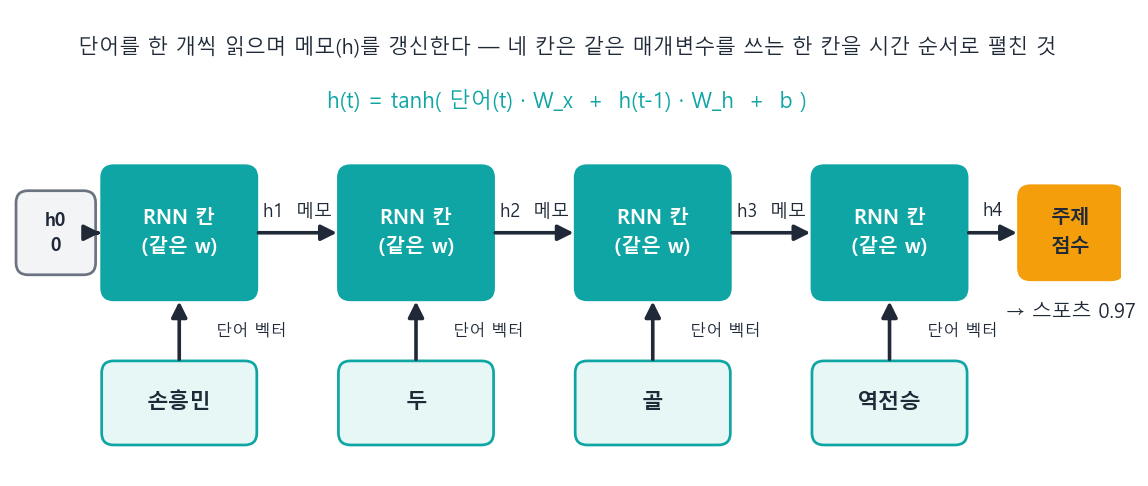<div style="color:#6B7280;font-size:0.9em;margin-top:4px;">같은 ‘RNN 칸’을 단어 수만큼 되풀이해 쓰므로 ‘순환’입니다. 그림은 그것을 시간 순서로 펼쳐 그린 것입니다.</div></div>

코드로 쓰면 6주차의 `for` 문 하나입니다. 이것이 RNN 의 전부입니다.

```python
h = 0으로 채운 메모
for 단어 in 문장:
    h = tanh(단어벡터 @ W_x + h @ W_h + b)      # 새 메모 = (이번 단어, 이전 메모) 로 계산
주제확률 = softmax(h @ W_o + b_o)
```

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 RNN 을 한 줄로</b><br><b>이전 메모와 이번 단어로 새 메모를 만드는 일을 단어 수만큼 반복한다.</b> 그래서 ‘순서’가 반영됩니다. 메모 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">h</code> 를 <b>은닉 상태(hidden state)</b> 라고 부릅니다. 단어 번호를 숫자 묶음(벡터)으로 바꾸는 표 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">E</code> 는 <b>임베딩(embedding)</b> 이라고 합니다. 매개변수는 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">E</code>, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">W_x</code>, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">W_h</code>, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">b</code>, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">W_o</code>, <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">b_o</code> 여섯 묶음이고, 전부 2-3 처럼 학습으로 정해집니다.</div><details style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#6B7280;font-weight:bold;">📎 LSTM · GRU · 트랜스포머는 무엇인가</summary><div style="margin-top:8px;">단순 RNN 은 문장이 길어지면 앞쪽 단어를 잊습니다(기울기 소실). 메모에 ‘문’을 달아 무엇을 기억하고 잊을지 조절하는 <b>LSTM</b>(1997) 과 <b>GRU</b>(2014) 가 그래서 나왔습니다. 2017년의 <b>트랜스포머(Transformer)</b> 는 단어를 하나씩 읽는 대신 모든 단어를 <b>한꺼번에</b> 보고 서로 얼마나 관련 있는지(어텐션)를 계산합니다. 챗GPT 의 T 가 그것입니다. 오늘 배우는 ‘단어를 숫자로 → 메모 → 점수 → softmax → 손실 → 학습’은 이들 모두에 그대로 들어 있습니다.</div></details>

## 3-2. 데이터 준비 — CSV 읽기

훈련 데이터는 뉴스 제목 160개입니다(주제별 40개). 수업용으로 만든 짧은 제목들입니다. 아래 셀을 실행하면 `news.csv` 파일이 만들어집니다.

In [ ]:
%%writefile news.csv
text,label
손흥민 두 골 폭발 토트넘 역전승,스포츠
한국 야구 대표팀 결승 진출,스포츠
프로야구 개막전 만원 관중 열기,스포츠
김연아 피겨 갈라쇼 전석 매진,스포츠
월드컵 예선 한국 대표팀 승리,스포츠
프로축구 K리그 우승 경쟁 치열,스포츠
마라톤 대회 참가자 기록 경신,스포츠
농구 대표팀 역전승으로 결승 진출,스포츠
배구 여자 대표팀 올림픽 티켓 확보,스포츠
골프 박세리 은퇴 경기 감동,스포츠
올림픽 양궁 대표팀 금메달 획득,스포츠
축구 국가대표 평가전 무승부,스포츠
프로야구 홈런왕 경쟁 막판 스퍼트,스포츠
테니스 결승 접전 끝에 우승,스포츠
수영 대표팀 아시안게임 금메달 기록,스포츠
야구 한국시리즈 7차전 역전 우승,스포츠
축구 손흥민 리그 득점왕 등극,스포츠
농구 결승 연장 승부 끝 우승,스포츠
배구 리그 개막 첫 경기 승리,스포츠
올림픽 태권도 대표팀 금메달 추가,스포츠
스키 점프 대표팀 월드컵 출전,스포츠
핸드볼 결승 진출 메달 확보,스포츠
육상 100m 한국 기록 경신,스포츠
프로축구 득점왕 시즌 20호 골,스포츠
배드민턴 대표팀 결승 우승 확정,스포츠
야구 대표팀 평가전 역전승,스포츠
피겨 대표팀 올림픽 티켓 획득,스포츠
축구 결승 승부차기 끝 우승,스포츠
농구 리그 득점왕 경쟁 치열,스포츠
마라톤 금메달 한국 기록 경신,스포츠
야구 개막전 홈런 두 방 승리,스포츠
축구 대표팀 월드컵 본선 진출 확정,스포츠
골프 대회 우승 상금 기록 경신,스포츠
배구 결승 역전승 우승 감동,스포츠
올림픽 수영 금메달 한국 기록,스포츠
프로야구 관중 100만 돌파 열기,스포츠
테니스 대표팀 아시안게임 금메달,스포츠
농구 대표팀 월드컵 첫 승리,스포츠
양궁 결승 접전 끝 금메달 획득,스포츠
축구 리그 개막전 손흥민 골 승리,스포츠
코스피 사상 최고치 경신 마감,경제
금리 인상에 대출 이자 부담 증가,경제
환율 급등 수출 기업 실적 개선,경제
반도체 수출 호조 무역수지 흑자,경제
물가 상승률 3퍼센트 소비 위축,경제
은행 예금 금리 인하 전망,경제
부동산 거래 감소 집값 하락세,경제
중소기업 대출 연체율 상승 우려,경제
주식 시장 외국인 매수 증가,경제
원유 가격 급등 물가 상승 압박,경제
수출 증가로 경제 성장률 상향,경제
코스닥 급락 투자자 손실 확대,경제
기업 실적 발표 주가 상승,경제
환율 하락 수입 물가 안정,경제
금리 동결 결정 대출 시장 안도,경제
부동산 세금 개편 집값 영향,경제
소비 심리 회복 소매 판매 증가,경제
주식 배당 확대 투자자 관심,경제
은행 대출 심사 강화 소비자 불만,경제
무역 적자 전환 수출 감소 영향,경제
반도체 기업 투자 확대 고용 증가,경제
물가 안정 금리 인하 기대감,경제
환율 변동 기업 실적 불확실성,경제
코스피 외국인 매도에 하락 마감,경제
경제 성장률 전망치 하향 조정,경제
부동산 대출 규제 거래 위축,경제
수출 기업 환율 상승 수혜,경제
주가 급등 투자자 매수 행렬,경제
금리 인상 예금 상품 인기,경제
소비 회복 기업 매출 증가,경제
코스피 급등 외국인 매수 확대,경제
금리 인하 기대 주식 시장 상승,경제
반도체 수출 증가 경제 성장 견인,경제
부동산 집값 상승 대출 수요 증가,경제
물가 상승 소비 위축 기업 매출 감소,경제
은행 금리 인상 예금 증가,경제
환율 급등 수입 물가 상승 압박,경제
주식 투자자 손실 코스닥 하락,경제
수출 감소 경제 성장률 하향,경제
기업 고용 확대 소비 심리 회복,경제
전국 폭염 경보 낮 최고 36도,날씨
태풍 북상 남부 지방 강풍 주의,날씨
장마 시작 전국 흐리고 비,날씨
한파 경보 아침 기온 영하 15도,날씨
미세먼지 나쁨 외출 자제 권고,날씨
주말 전국 맑음 큰 일교차 주의,날씨
폭설 예보 강원 산간 30센티,날씨
황사 유입 전국 공기질 나쁨,날씨
집중호우 호우 경보 하천 범람 주의,날씨
열대야 지속 밤 기온 25도 이상,날씨
태풍 상륙 제주 항공편 결항,날씨
기온 급락 내일 아침 서리 주의,날씨
오후 소나기 우산 챙기세요,날씨
안개 주의 아침 출근길 시야 불량,날씨
폭염 지속 전력 수요 최고치,날씨
장마 소강 주말 맑고 더위,날씨
한파 지속 수도관 동파 주의,날씨
강풍 주의보 바다 높은 파도,날씨
미세먼지 좋음 맑은 하늘 전망,날씨
폭설 뒤 빙판길 교통 주의,날씨
내일 전국 비 기온 하락,날씨
태풍 영향 전국 강한 비바람,날씨
봄비 뒤 기온 상승 포근한 날씨,날씨
폭염 경보 확대 온열 질환 주의,날씨
황사 뒤 미세먼지 농도 상승,날씨
한파 영하 10도 출근길 주의,날씨
가을 맑은 하늘 큰 일교차,날씨
집중호우 산사태 경보 발령,날씨
주말 눈 예보 교통 혼잡 우려,날씨
장마 끝 폭염 시작 전망,날씨
내일 아침 기온 영하 한파 주의,날씨
태풍 북상 주말 전국 비 예보,날씨
폭염 경보 낮 기온 35도 전망,날씨
미세먼지 나쁨 내일 황사 유입,날씨
폭설 예보 내일 출근길 교통 주의,날씨
장마 지속 전국 비 하천 범람 주의,날씨
주말 맑음 기온 상승 나들이 날씨,날씨
강풍 주의보 내일 전국 비바람,날씨
한파 경보 전국 기온 급락,날씨
오후 소나기 뒤 맑은 하늘 전망,날씨
김치찌개 맛있게 끓이는 비법,음식
서울 맛집 추천 돼지갈비 명가,음식
집에서 만드는 바삭한 치킨 레시피,음식
제철 과일 딸기 디저트 만들기,음식
된장찌개 깊은 맛 내는 재료,음식
비빔밥 색깔 고운 나물 손질법,음식
맛집 투어 부산 돼지국밥 추천,음식
라면 더 맛있게 끓이는 비법,음식
불고기 양념 황금 레시피 공개,음식
떡볶이 매운맛 조절 방법,음식
냉면 육수 시원하게 만드는 비법,음식
빵집 추천 크루아상 맛있는 집,음식
삼겹살 굽는 법 맛있는 비결,음식
파스타 소스 집에서 만들기,음식
김밥 재료 손질 말기 요령,음식
전주 맛집 비빔밥 추천 명소,음식
카페 디저트 치즈케이크 레시피,음식
잡채 당면 삶는 시간 비법,음식
초밥 맛집 신선한 재료 추천,음식
부대찌개 맛있게 끓이는 레시피,음식
호떡 반죽 바삭하게 굽는 법,음식
닭갈비 양념 레시피 매운맛 비법,음식
빙수 디저트 집에서 만들기,음식
갈비탕 국물 진하게 끓이는 비법,음식
피자 도우 집에서 만드는 레시피,음식
칼국수 맛집 추천 진한 국물,음식
감자탕 맛있게 끓이는 재료 손질,음식
만두 속 재료 맛있는 비법,음식
토스트 레시피 아침 간단 요리,음식
순두부찌개 매운맛 레시피 추천,음식
김치찌개 레시피 맛집 비법 공개,음식
집에서 만드는 떡볶이 매운맛 레시피,음식
치킨 맛집 추천 바삭한 비결,음식
된장찌개 맛있게 끓이는 재료 비법,음식
디저트 카페 추천 딸기 케이크,음식
삼겹살 맛집 추천 양념 비법,음식
라면 레시피 집에서 맛있게 끓이는 법,음식
비빔밥 맛집 추천 나물 재료,음식
파스타 레시피 소스 맛있게 만들기,음식
국밥 맛집 추천 진한 국물 비법,음식

11주차에 배운 파일 읽기입니다. 표준 라이브러리 `csv` 모듈이 쉼표로 나누고 첫 줄을 열 이름으로 씁니다.

**예상해 보기** — `rows[0]` 은 어떤 모양일까요? 리스트일까요, 딕셔너리일까요?

In [ ]:
import csv

with open("news.csv", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))          # 한 줄 → {"text": ..., "label": ...}

print(len(rows), "건")
print(rows[0])
print(rows[-1])

In [ ]:
counts = {}
for row in rows:
    counts[row["label"]] = counts.get(row["label"], 0) + 1    # 6주차 딕셔너리 세기 패턴
print(counts)

## 3-3. 훈련셋과 테스트셋 나누기

160건을 섞은 뒤 앞 80%(128건)를 훈련셋, 뒤 20%(32건)를 테스트셋으로 둡니다. **섞는 이유**: 파일이 주제별로 정렬돼 있어서, 안 섞으면 테스트셋이 전부 ‘음식’이 됩니다. `random.seed(0)` 은 누가 실행해도 같은 순서로 섞이게 합니다.

In [ ]:
import random

random.seed(0)
random.shuffle(rows)                       # 제자리에서 섞는다

n_train = int(len(rows) * 0.8)
train_rows = rows[:n_train]
test_rows = rows[n_train:]
print("훈련셋", len(train_rows), "건  /  테스트셋", len(test_rows), "건")
print("훈련셋 첫 줄:", train_rows[0])

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">✏️ 실습 3-1</span>&nbsp; <b>테스트셋의 주제 분포</b> <span style="color:#6B7280;font-weight:normal;">(약 3분)</span><br>테스트셋 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">test_rows</code> 에 주제가 몇 건씩 들어 있는지 세어 딕셔너리 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">test_counts</code> 에 넣으세요. 3-2 의 세기 패턴 그대로입니다.<br>예상해 보기: 32건이 네 주제에 꼭 8건씩일까요? 섞었으니 조금 다를 수 있습니다.</div>

In [ ]:
# 여기에 test_counts 를 만드세요


print(test_counts)

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("실습 3-1", lambda: sum(test_counts.values()) == 32 and set(test_counts) == {"스포츠", "경제", "날씨", "음식"} and test_counts == {r["label"]: sum(1 for t in test_rows if t["label"] == r["label"]) for r in test_rows})

<details style="background:#FFFFFF;color:#1F2937;border:1px dashed #FF6B5A;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#FF6B5A;font-weight:bold;">💡 ✏️ 실습 3-1 정답 예시 — 테스트셋의 주제 분포 (먼저 스스로 풀어 본 뒤 여세요)</summary><div style="margin-top:8px;"><pre style="background:#1F2937;color:#F9FAFB;padding:14px 16px;border-radius:10px;font-family:Consolas,monospace;line-height:1.5;white-space:pre-wrap;overflow-wrap:anywhere;box-sizing:border-box;max-width:100%;">test_counts = {}
for row in test_rows:
    test_counts[row[&quot;label&quot;]] = test_counts.get(row[&quot;label&quot;], 0) + 1

print(test_counts)</pre></div></details>

## 3-4. 전처리 — 번호의 열로

2-4 에서 만든 도구를 **훈련셋에** 적용합니다. 어휘 사전은 **훈련셋으로만** 만듭니다. 주제 이름도 번호로 바꿉니다(`labels.index`).

**예상해 보기** — 테스트셋 단어 가운데 사전에 없는 단어(`<unk>`)는 몇 퍼센트쯤일까요?

In [ ]:
labels = ["스포츠", "경제", "날씨", "음식"]

vocab = {"<unk>": 0}
for row in train_rows:                       # 훈련셋으로만!
    for word in row["text"].split():
        if word not in vocab:
            vocab[word] = len(vocab)
print("어휘 수:", len(vocab))

def encode(sentence, vocab):
    return [vocab.get(word, 0) for word in sentence.split()]

train_x = [encode(row["text"], vocab) for row in train_rows]     # 번호의 열들
train_y = [labels.index(row["label"]) for row in train_rows]     # 주제 번호들
test_x = [encode(row["text"], vocab) for row in test_rows]
test_y = [labels.index(row["label"]) for row in test_rows]

print(train_rows[0]["text"], "→", train_x[0], "/ 주제", train_y[0], labels[train_y[0]])

In [ ]:
total = sum(len(ids) for ids in test_x)
unknown = sum(ids.count(0) for ids in test_x)
print(f"테스트셋 단어 {total}개 가운데 모르는 단어 {unknown}개 ({unknown / total:.0%})")

<div style="background:#FFF0EE;color:#1F2937;border-left:6px solid #FF6B5A;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#FF6B5A;">⚠️ 모르는 단어가 이렇게 많다</b><br>테스트셋 단어의 40% 가까이가 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&lt;unk&gt;</code> 입니다. 띄어쓰기 토큰화 때문에 ‘대표팀’과 ‘대표팀이’가 다른 단어가 되고, 160개짜리 작은 데이터라 처음 보는 단어가 많습니다. 모델은 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&lt;unk&gt;</code> 에 대해 아무것도 모릅니다. 그런데도 분류가 되는지, 어디서 틀리는지 곧 봅니다. <b>데이터가 많을수록, 토큰화가 좋을수록</b> 이 비율이 줄어듭니다.</div>

## 3-5. 라이브러리 가져오기 — `minirnn`

이제 모델입니다. 수업 사이트의 Python 은 브라우저 안에서 돌아서 PyTorch 를 쓸 수 없습니다. 그래서 오늘은 **`numpy` 만으로 만든 작은 RNN 라이브러리 `minirnn`** 을 씁니다. 아래 셀이 그 라이브러리입니다. 접혀 있지만 펼쳐 볼 수 있습니다. 3-1 의 `for` 문이 `forward()` 안에 그대로 있습니다. 학습(`_step`)은 2-3 의 ‘오차 × x’ 를 매개변수 여섯 묶음에 대해 하는 것입니다. 지금 다 읽을 필요는 없습니다. **쓰는 법만** 보면 됩니다.

실행하면 `minirnn.py` 파일이 만들어집니다. 9주차에 `shapes.py` 를 만든 것과 같습니다.

In [ ]:
%%writefile minirnn.py
# 📦 minirnn.py — 수업용 작은 RNN 라이브러리 (실행하면 파일이 만들어집니다 · 접힌 셀은 펼쳐 볼 수 있음)
"""minirnn — 수업용 아주 작은 RNN 문서 분류 라이브러리 (numpy 만 사용)

사용법:
    model = RNNClassifier(vocab_size, num_classes)   # 모델 만들기
    history = model.fit(train_x, train_y, epochs=20) # 학습
    model.predict(ids)                               # 추론: 번호 열 → 주제 번호
    model.predict_proba(ids)                         # 추론: 주제별 확률
    model.score(x, y)                                # 정확도
"""
import numpy as np


def softmax(scores):
    """점수 묶음을 합이 1 인 확률로 바꾼다"""
    e = np.exp(scores - scores.max())
    return e / e.sum()


class RNNClassifier:
    def __init__(self, vocab_size, num_classes, embed_dim=32, hidden_dim=64, seed=0):
        rng = np.random.default_rng(seed)
        s = 0.1                                               # 처음에는 작은 무작위 숫자로 채운다
        self.E = rng.normal(0, s, (vocab_size, embed_dim))    # 단어 번호 → 단어 벡터 (임베딩)
        self.W_x = rng.normal(0, s, (embed_dim, hidden_dim))  # 단어 벡터 → 메모
        self.W_h = rng.normal(0, s, (hidden_dim, hidden_dim)) # 이전 메모 → 메모
        self.b_h = np.zeros(hidden_dim)
        self.W_o = rng.normal(0, s, (hidden_dim, num_classes))# 마지막 메모 → 주제 점수
        self.b_o = np.zeros(num_classes)
        self.hidden_dim = hidden_dim

    # ---------- 추론: 앞으로 계산 ----------
    def forward(self, ids):
        """단어를 한 개씩 읽으며 메모(h)를 갱신하고, 마지막 메모로 주제 확률을 낸다."""
        h = np.zeros(self.hidden_dim)                         # 처음 메모는 0
        hs, xs = [h], []
        for i in ids:
            x = self.E[i]                                     # 단어 번호 → 단어 벡터
            h = np.tanh(x @ self.W_x + h @ self.W_h + self.b_h)   # 새 메모 = f(단어, 이전 메모)
            xs.append(x); hs.append(h)
        probs = softmax(h @ self.W_o + self.b_o)              # 마지막 메모 → 주제 확률
        return probs, hs, xs

    def predict_proba(self, ids):
        return self.forward(ids)[0]

    def predict(self, ids):
        return int(np.argmax(self.predict_proba(ids)))

    # ---------- 학습: 틀린 만큼 되돌아가며 고치기 ----------
    def _step(self, ids, y, lr):
        probs, hs, xs = self.forward(ids)
        loss = -np.log(probs[y] + 1e-12)                      # 교차 엔트로피: 정답 확률이 낮을수록 큰 값
        d_out = probs.copy(); d_out[y] -= 1                   # 손실의 기울기 (softmax + 교차 엔트로피)
        gW_o = np.outer(hs[-1], d_out); gb_o = d_out
        gW_x = np.zeros_like(self.W_x); gW_h = np.zeros_like(self.W_h); gb_h = np.zeros_like(self.b_h)
        gE = {}
        dh = d_out @ self.W_o.T
        for t in range(len(ids) - 1, -1, -1):                 # 시간을 거슬러 올라간다 (BPTT)
            dz = dh * (1 - hs[t + 1] ** 2)                    # tanh 의 미분
            gW_x += np.outer(xs[t], dz); gW_h += np.outer(hs[t], dz); gb_h += dz
            gE[ids[t]] = gE.get(ids[t], 0) + dz @ self.W_x.T
            dh = dz @ self.W_h.T
        for g in (gW_x, gW_h, gb_h, gW_o, gb_o):
            np.clip(g, -5, 5, out=g)                          # 기울기가 너무 커지지 않게
        self.W_x -= lr * gW_x; self.W_h -= lr * gW_h; self.b_h -= lr * gb_h
        self.W_o -= lr * gW_o; self.b_o -= lr * gb_o
        for i, g in gE.items():
            self.E[i] -= lr * np.clip(g, -5, 5)
        return loss

    def fit(self, X, y, epochs=20, lr=0.05, seed=0, verbose=True):
        """훈련 데이터를 epochs 번 돌며 매개변수를 고친다. (손실, 정확도) 기록을 돌려준다."""
        rng = np.random.default_rng(seed)
        history = []
        order = np.arange(len(X))
        for ep in range(1, epochs + 1):
            rng.shuffle(order)                                # 에포크마다 순서를 섞는다
            total = 0.0
            for i in order:
                total += self._step(X[i], y[i], lr)
            loss = total / len(X)
            acc = self.score(X, y)
            history.append((loss, acc))
            if verbose and (ep == 1 or ep % 5 == 0 or ep == epochs):
                print(f"에포크 {ep:3d}   손실 {loss:.3f}   훈련 정확도 {acc:.2f}")
        return history

    def score(self, X, y):
        """정확도 = 맞힌 개수 / 전체 개수"""
        return sum(self.predict(ids) == t for ids, t in zip(X, y)) / len(X)

외부 라이브러리를 처음 만났을 때 하는 일 두 가지입니다. `import` 하고, `help` 로 쓰는 법을 읽습니다.

In [ ]:
import numpy as np                  # minirnn 이 쓰는 numpy 를 먼저 불러옵니다 (수업 사이트는 이 순간 패키지를 받아옵니다)
import minirnn

help(minirnn)                       # 모듈 맨 위 독스트링 — 쓰는 법이 적혀 있습니다

## 3-6. 모델 만들기와 학습

쓰는 법을 읽었으니 패턴대로 갑니다. **모델 만들기 → `fit`**. 어휘 수와 주제 수를 알려 주면 매개변수를 작은 무작위 숫자로 채워 둡니다.

**예상해 보기** — 학습 전의 모델은 네 주제 가운데 하나를 찍는 셈입니다. 훈련 정확도가 얼마쯤 나올까요?

In [ ]:
model = minirnn.RNNClassifier(vocab_size=len(vocab), num_classes=len(labels))

print("학습 전 훈련 정확도:", round(model.score(train_x, train_y), 2))     # 찍는 수준 — 0.25 근처
print("학습 전 첫 문장 확률:", model.predict_proba(train_x[0]).round(2))  # 네 주제가 거의 같다

이제 학습입니다. 훈련셋 128건을 20바퀴(에포크) 돕니다. 바퀴마다 손실과 훈련 정확도를 찍습니다.

**예상해 보기** — 손실은 어떻게 변할까요? 2-3 과 같은 모양일까요?

In [ ]:
history = model.fit(train_x, train_y, epochs=20, lr=0.05)

손실이 1.38 → 0.00x 로 떨어지고 훈련 정확도가 1.00 이 됩니다. 1.38 은 우연이 아닙니다. 네 주제를 똑같이 찍을 때의 손실 −log(1/4) = 1.386 입니다. 거기서 출발해 ‘틀린 만큼 되돌아가며 고치기’를 128 × 20 번 한 결과입니다. 그래프로 봅니다.

In [ ]:
import matplotlib.pyplot as plt

losses = [loss for loss, acc in history]
accs = [acc for loss, acc in history]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
ax1.plot(range(1, 21), losses, marker="o", color="#FF6B5A"); ax1.set_title("loss"); ax1.set_xlabel("epoch")
ax2.plot(range(1, 21), accs, marker="o", color="#0EA5A4"); ax2.set_title("train accuracy"); ax2.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 3-7. 평가 — 테스트셋으로 실력 재기

훈련 정확도 1.00 은 **문제집 점수**입니다. 떼어 둔 테스트셋으로 **모의고사**를 봅니다.

**예상해 보기** — 테스트 정확도도 1.00 일까요? 모르는 단어가 40% 였습니다.

In [ ]:
print("훈련 정확도  :", round(model.score(train_x, train_y), 2))
print("테스트 정확도:", round(model.score(test_x, test_y), 2))

In [ ]:
print("틀린 것들:")
for ids, y, row in zip(test_x, test_y, test_rows):
    pred = model.predict(ids)
    if pred != y:
        unknown = [w for w in row["text"].split() if w not in vocab]
        print(f"  {row['text']!r:40s} 정답 {labels[y]} → 예측 {labels[pred]}   모르는 단어 {unknown}")

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 훈련 1.00 vs 테스트 0.8x — 과적합과 모르는 단어</b><br>① 훈련셋은 다 맞히고 테스트셋은 일부 틀립니다. 모델이 훈련 제목을 <b>외운</b> 부분이 있다는 뜻입니다. 이것이 <b>과적합</b>입니다. 손실이 0.00x 까지 떨어진 것이 그 신호입니다.<br>② 틀린 제목을 보면 <b>모르는 단어</b>가 많습니다. 모델은 본 적 있는 것만 압니다. 모르는 단어가 없는데도 틀리는 제목이 있다면, 그 단어들의 <b>조합</b>을 훈련셋에서 충분히 보지 못한 것입니다. 데이터 160건의 한계입니다.<br>③ 그래도 160건으로 80% 안팎을 맞힙니다. 규칙을 한 줄도 쓰지 않았는데 말입니다. 실제 서비스는 데이터가 수만 ~ 수백만 건이라 훨씬 정확합니다.<br>④ <b>테스트 정확도가 진짜 점수</b>입니다. 훈련 정확도만 보고하는 것은 문제집 점수를 성적표에 적는 것과 같습니다.</div>

## 3-8. 추론 — 새 제목 분류하기

마지막 단계입니다. 데이터에 없던 새 제목을 넣어 봅니다. `predict_proba` 는 네 주제의 확률을, `predict` 는 가장 큰 것의 번호를 돌려줍니다.

**예상해 보기** — 네 번째 “학교 축제 공연 성황”은 어떻게 될까요? 네 단어 모두 사전에 없습니다.

In [ ]:
new_titles = ["손흥민 결승 골 우승", "금리 인하 주가 상승", "내일 폭염 주의", "김치찌개 레시피 추천",
              "학교 축제 공연 성황"]

for title in new_titles:
    ids = encode(title, vocab)
    probs = model.predict_proba(ids)
    print(f"{title:18s} → {labels[model.predict(ids)]:4s}  확률 {probs.round(2)}   번호 {ids}")

<div style="background:#FFF7E6;color:#1F2937;border-left:6px solid #F59E0B;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#B45309;">🤔 생각해 보기</b><br>“학교 축제 공연 성황”은 번호가 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">[0, 0, 0, 0]</code> 입니다. 모델에게는 ‘모르는 단어 네 개’입니다. 그런데도 어떤 주제를 <b>자신 있게</b> 답합니다. 왜 그럴까요? 이 답을 믿어도 될까요?<br>실제 서비스라면 어떻게 해야 할까요? (힌트: 확률이 고르게 퍼져 있거나 모르는 단어가 대부분이면 ‘판단 보류’를 답하게 할 수 있습니다.)</div>

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">✏️ 실습 3-2</span>&nbsp; <b>새 제목 분류하기</b> <span style="color:#6B7280;font-weight:normal;">(약 4분)</span><br>제목 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&quot;야구 대표팀 결승 역전승&quot;</code> 을 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">encode</code> → <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">model.predict</code> 로 분류해, 예측 주제 <b>이름</b>을 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">pred_label</code> 에, 네 주제의 확률을 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">pred_probs</code> 에 넣으세요.<br>그리고 직접 제목을 하나 지어 분류해 보세요. 사전에 있는 단어를 쓰면 잘 맞히고, 없는 단어를 쓰면 엉뚱해집니다.</div>

In [ ]:
title = "야구 대표팀 결승 역전승"

# 여기에 pred_label 과 pred_probs 를 만드세요


print(pred_label, pred_probs.round(2))

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("실습 3-2", lambda: pred_label == "스포츠" and pred_label == labels[model.predict(encode("야구 대표팀 결승 역전승", vocab))] and abs(pred_probs.sum() - 1) < 1e-6 and pred_probs.argmax() == 0)

<details style="background:#FFFFFF;color:#1F2937;border:1px dashed #FF6B5A;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#FF6B5A;font-weight:bold;">💡 ✏️ 실습 3-2 정답 예시 — 새 제목 분류하기 (먼저 스스로 풀어 본 뒤 여세요)</summary><div style="margin-top:8px;"><pre style="background:#1F2937;color:#F9FAFB;padding:14px 16px;border-radius:10px;font-family:Consolas,monospace;line-height:1.5;white-space:pre-wrap;overflow-wrap:anywhere;box-sizing:border-box;max-width:100%;">title = &quot;야구 대표팀 결승 역전승&quot;

ids = encode(title, vocab)
pred_label = labels[model.predict(ids)]
pred_probs = model.predict_proba(ids)

print(pred_label, pred_probs.round(2))      # 스포츠 [0.99 ...]</pre></div></details>

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">✏️ 실습 3-3</span>&nbsp; <b>에포크를 줄이면</b> <span style="color:#6B7280;font-weight:normal;">(약 5분)</span><br>새 모델 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">model_short</code> 를 만들어 <b>에포크 5</b>로만 학습시키고, 테스트 정확도를 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">acc_short</code> 에 넣으세요. (<code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">minirnn.RNNClassifier(...)</code> 로 새로 만들어야 합니다. <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">model</code> 을 다시 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">fit</code> 하면 이어서 학습됩니다.)<br>예상해 보기: 20 에포크짜리 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">model</code> 보다 테스트 정확도가 높을까요, 낮을까요? 훈련 정확도는요? 결과를 보고 ‘에포크를 늘리면 항상 좋은가’에 답해 보세요.</div>

In [ ]:
# 여기에 model_short 를 만들고 5 에포크 학습시킨 뒤 acc_short 를 구하세요


print("5 에포크 테스트 정확도:", round(acc_short, 2))

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("실습 3-3", lambda: isinstance(model_short, minirnn.RNNClassifier) and abs(acc_short - model_short.score(test_x, test_y)) < 1e-9 and 0 < acc_short <= 1)

<details style="background:#FFFFFF;color:#1F2937;border:1px dashed #FF6B5A;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#FF6B5A;font-weight:bold;">💡 ✏️ 실습 3-3 정답 예시 — 에포크를 줄이면 (먼저 스스로 풀어 본 뒤 여세요)</summary><div style="margin-top:8px;"><pre style="background:#1F2937;color:#F9FAFB;padding:14px 16px;border-radius:10px;font-family:Consolas,monospace;line-height:1.5;white-space:pre-wrap;overflow-wrap:anywhere;box-sizing:border-box;max-width:100%;">model_short = minirnn.RNNClassifier(vocab_size=len(vocab), num_classes=len(labels))
model_short.fit(train_x, train_y, epochs=5, lr=0.05)
acc_short = model_short.score(test_x, test_y)

print(&quot;5 에포크 테스트 정확도:&quot;, round(acc_short, 2))
# 훈련 정확도가 아직 1.00 이 아닌데도 테스트 정확도는 20 에포크와 비슷하거나 더 높을 수 있습니다.
# 에포크를 늘리면 훈련 손실은 계속 줄지만 테스트 정확도는 어느 순간부터 좋아지지 않습니다 — 과적합.</pre></div></details>

## 3-9. 같은 일을 PyTorch 로 쓰면 (참고)

오늘 `minirnn` 으로 한 일을 실제 현장에서는 **PyTorch** 로 합니다. 아래는 같은 문제를 PyTorch 로 쓴 것입니다. 수업 사이트에서는 돌지 않습니다(PyTorch 는 브라우저용 빌드가 없습니다). PC 나 Google Colab 에서 `pip install torch` 뒤에 실행할 수 있습니다. **모양이 같다**는 것만 보세요. 모델 만들기 → 손실 → 에포크 반복 → 평가.

<details style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#6B7280;font-weight:bold;">📎 PyTorch 판 — 모델 정의 · 학습 · 평가 (PC · Colab 용)</summary><div style="margin-top:8px;"><pre style="background:#1F2937;color:#F9FAFB;padding:14px 16px;border-radius:10px;font-family:Consolas,monospace;line-height:1.5;white-space:pre-wrap;overflow-wrap:anywhere;box-sizing:border-box;max-width:100%;">import torch, torch.nn as nn

class RNNClassifier(nn.Module):                       # 9주차 상속 — nn.Module 을 물려받는다
    def __init__(self, vocab_size, num_classes, embed_dim=32, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)   # minirnn 의 E
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)  # W_x · W_h · b 가 안에 있다
        self.fc = nn.Linear(hidden_dim, num_classes)           # W_o · b_o

    def forward(self, ids):                            # minirnn 의 forward 와 같은 일
        x = self.embedding(ids)                        # 번호 → 단어 벡터
        _, h = self.rnn(x)                             # 단어를 차례로 읽은 마지막 메모
        return self.fc(h[-1])                          # 메모 → 주제 점수 (softmax 는 손실 함수 안에서)

model = RNNClassifier(len(vocab), len(labels))
loss_fn = nn.CrossEntropyLoss()                        # 교차 엔트로피
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)   # ‘기울기 반대로 조금씩’을 대신 해 준다

for epoch in range(20):                                # 에포크
    total = 0
    for ids, y in zip(train_x, train_y):
        scores = model(torch.tensor([ids]))            # 예측
        loss = loss_fn(scores, torch.tensor([y]))      # 손실
        optimizer.zero_grad(); loss.backward()         # 기울기 자동 계산 (autograd)
        optimizer.step()                               # 매개변수 고치기
        total += loss.item()
    print(f&quot;에포크 {epoch + 1}  손실 {total / len(train_x):.3f}&quot;)

with torch.no_grad():                                  # 추론 — 기울기 계산 끄기
    correct = sum(model(torch.tensor([ids])).argmax().item() == y for ids, y in zip(test_x, test_y))
print(&quot;테스트 정확도&quot;, correct / len(test_x))</pre><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">loss.backward()</code> 한 줄이 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">minirnn._step</code> 의 기울기 계산 전부를 대신합니다. <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">nn.RNN</code> 을 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">nn.LSTM</code> 이나 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">nn.GRU</code> 로 바꾸면 더 좋은 모델이 됩니다. 참고 교재(Python for AI apps 9강)는 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">torchtext</code> 와 LSTM 을 쓴 판입니다.</div></details><details style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:10px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><summary style="cursor:pointer;color:#6B7280;font-weight:bold;">📎 scikit-learn 판 — RNN 없이 세 줄</summary><div style="margin-top:8px;"><pre style="background:#1F2937;color:#F9FAFB;padding:14px 16px;border-radius:10px;font-family:Consolas,monospace;line-height:1.5;white-space:pre-wrap;overflow-wrap:anywhere;box-sizing:border-box;max-width:100%;">from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

vectorizer = CountVectorizer()                                   # 단어 세기 (bag of words)
clf = MultinomialNB().fit(vectorizer.fit_transform(train_texts), train_labels)   # 모델 만들기 + fit
print(clf.predict(vectorizer.transform([&quot;손흥민 결승 골 우승&quot;])))               # predict</pre>순서를 무시하고 ‘어떤 단어가 몇 번 나왔나’만 세는 고전 방법입니다. 짧은 제목 분류는 이것으로도 충분히 잘 됩니다. 단계와 쓰는 법(<code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">fit</code> · <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">predict</code>)이 같다는 점을 보세요.</div></details>

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 3교시 정리</b><br>① <b>RNN</b> = 이전 메모와 이번 단어로 새 메모를 만드는 일을 단어 수만큼 반복. 마지막 메모로 주제 점수.<br>② 응용은 일곱 단계 — <b>데이터 → 나누기 → 전처리 → 모델 → 학습 → 평가 → 추론</b>. 각 단계는 함수 한두 개.<br>③ 라이브러리는 <b><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">import</code> → 모델 만들기 → <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">fit</code> → <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">predict</code></b>. <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">minirnn</code> 도 PyTorch 도 scikit-learn 도 같은 모양.<br>④ 훈련 정확도가 아니라 <b>테스트 정확도</b>가 실력. 손실이 0 에 가까운데 테스트가 안 오르면 <b>과적합</b>.<br>⑤ 모델은 <b>본 적 있는 것만</b> 압니다. 모르는 단어가 많은 입력에는 자신 있게 틀립니다. 데이터의 양과 질이 모델의 한계를 정합니다.</div>

# 12주차 정리

| 용어 | 한 줄 | 오늘 코드에서 |
|:---|:---|:---|
| 문제 정의 | 불편 → 입력 · 출력 · 범위. 세 질문에 답하지 못하면 아직 문제가 아니다 | 실습 1-1 의 `my_problems` |
| 모델 · 매개변수 | 입력 → 출력 함수. 안의 숫자를 데이터로 정한다 | `w`, `minirnn.RNNClassifier(...)` |
| 학습 · 손실 · 에포크 | 손실이 줄어드는 쪽으로 조금씩 고치는 반복. 한 바퀴 = 에포크 | `w -= lr * error * x`, `model.fit(..., epochs=20)` |
| 추론 | 학습된 모델에 새 입력을 넣어 답을 받는다 | `w * 10`, `model.predict(ids)` |
| 훈련셋 · 테스트셋 · 과적합 | 떼어 둔 테스트셋 점수가 진짜 실력 | `rows[:n_train]`, `model.score(test_x, test_y)` |
| 토큰화 · 어휘 사전 · `<unk>` | 글 → 조각 → 번호의 열 | `split()`, `vocab`, `encode()` |
| RNN · 은닉 상태 · 임베딩 | 단어를 한 개씩 읽으며 메모를 갱신 | `forward()` 의 `for` 문 |
| 라이브러리 패턴 | `import` → 모델 → `fit` → `predict` | `import minirnn`, PyTorch, scikit-learn |

<div style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#6B7280;">📎 오늘 쓴 것과 실제 현장의 거리</b><br>오늘 모델은 매개변수 약 2만 개, 데이터 160건, 브라우저에서 몇 초 학습입니다. 현장의 문서 분류 모델은 매개변수 수억 개, 데이터 수백만 건, GPU 로 몇 시간입니다. 그러나 <b>단계는 같고 코드의 모양도 같습니다.</b> 2교시 표의 라이브러리 이름과 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">fit</code> · <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">predict</code> 패턴을 기억하면, 공식 문서의 Quickstart 를 읽고 따라 할 수 있습니다. 그것이 ‘라이브러리를 가져다 쓸 줄 안다’는 뜻입니다.</div>

# 📝 12주차 과제

<div style="background:#F3F4F6;color:#1F2937;border-left:6px solid #6B7280;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#6B7280;">📎 과제를 풀기 전에</b><br>① 각 문제의 <b>🔍 자가 점검</b> 셀로 답을 스스로 확인할 수 있습니다. 과제에는 정답 예시가 없습니다.<br>② 주어진 함수 · 변수 이름을 바꾸지 마세요. 점검 셀이 그 이름으로 부릅니다.<br>③ 과제 4 · 5 는 3교시의 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">vocab</code> · <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">encode</code> · <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">train_x</code> 등이 있어야 합니다. 맨 위부터 차례로 실행한 뒤 푸세요.<br>④ 문법을 찾아보거나 생각을 정리하는 데 AI 도구를 쓸 수 있습니다. 다만 <b>AI가 작성한 코드를 그대로 제출하는 것은 금지</b>입니다(수업계획서). 제출한 코드는 스스로 설명할 수 있어야 합니다.</div>

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">📝 과제 1</span>&nbsp; <b>토큰화 함수</b><br><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">tokenize(text)</code> — 문장을 띄어쓰기로 나누되, 각 조각 끝의 문장 부호 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">.</code> <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">,</code> <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">!</code> <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">?</code> 를 떼고, 빈 조각은 버린 리스트를 돌려줍니다.<br>힌트: <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">word.strip(&quot;.,!?&quot;)</code>. 떼고 나서 빈 문자열이면 넣지 않습니다.<br><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">tokenize(&quot;손흥민 두 골, 토트넘 역전승!&quot;)</code> → <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">[&quot;손흥민&quot;, &quot;두&quot;, &quot;골&quot;, &quot;토트넘&quot;, &quot;역전승&quot;]</code></div>

In [ ]:
# 여기에 함수를 정의하세요


print(tokenize("손흥민 두 골, 토트넘 역전승!"))
print(tokenize("내일  비 ... 기온 하락?"))

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("과제 1", lambda: tokenize("손흥민 두 골, 토트넘 역전승!") == ["손흥민", "두", "골", "토트넘", "역전승"] and tokenize("내일  비 ... 기온 하락?") == ["내일", "비", "기온", "하락"] and tokenize("") == [] and tokenize("a, b. c!") == ["a", "b", "c"])

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">📝 과제 2</span>&nbsp; <b>어휘 사전 함수</b><br><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">build_vocab(sentences)</code> — 문장 리스트로 어휘 사전 딕셔너리를 만들어 돌려줍니다. <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">&quot;&lt;unk&gt;&quot;</code> 가 0번, 나머지는 **처음 나온 순서대로** 1, 2, 3, …. 토큰화는 과제 1 의 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">tokenize</code> 를 쓰세요.<br><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">build_vocab([&quot;금리 인상, 대출 부담&quot;, &quot;금리 인하!&quot;])</code> → <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">{&quot;&lt;unk&gt;&quot;: 0, &quot;금리&quot;: 1, &quot;인상&quot;: 2, &quot;대출&quot;: 3, &quot;부담&quot;: 4, &quot;인하&quot;: 5}</code></div>

In [ ]:
# 여기에 함수를 정의하세요


print(build_vocab(["금리 인상, 대출 부담", "금리 인하!"]))

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("과제 2", lambda: build_vocab(["금리 인상, 대출 부담", "금리 인하!"]) == {"<unk>": 0, "금리": 1, "인상": 2, "대출": 3, "부담": 4, "인하": 5} and build_vocab([]) == {"<unk>": 0} and len(build_vocab(["a a a", "b."])) == 3)

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">📝 과제 3</span>&nbsp; <b>정확도 함수</b><br><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">accuracy(predictions, answers)</code> — 예측 리스트와 정답 리스트를 받아 **맞힌 비율**을 실수로 돌려줍니다. 두 리스트 길이는 같습니다. 빈 리스트면 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">0.0</code>.<br>힌트: <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">zip</code> 으로 짝지어 같은 것을 셉니다. 6주차 세기 패턴.<br><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">accuracy([0, 1, 2, 2], [0, 1, 1, 2])</code> → <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">0.75</code></div>

In [ ]:
# 여기에 함수를 정의하세요


print(accuracy([0, 1, 2, 2], [0, 1, 1, 2]))

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("과제 3", lambda: abs(accuracy([0, 1, 2, 2], [0, 1, 1, 2]) - 0.75) < 1e-9 and accuracy([], []) == 0.0 and abs(accuracy(["a", "b"], ["a", "b"]) - 1.0) < 1e-9 and abs(accuracy([1, 1, 1], [0, 0, 1]) - 1 / 3) < 1e-9)

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">📝 과제 4</span>&nbsp; <b>테스트셋 예측 모아 보기</b><br>3교시의 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">model</code> 로 테스트셋 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">test_x</code> 전체를 예측한 번호 리스트를 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">test_preds</code> 에 넣고, 과제 3 의 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">accuracy</code> 로 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">test_y</code> 와 비교한 값을 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">test_acc</code> 에 넣으세요.<br><code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">test_acc</code> 는 3-7 의 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">model.score(test_x, test_y)</code> 와 같은 값이어야 합니다. 라이브러리의 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">score</code> 가 안에서 하는 일을 직접 해 보는 것입니다.</div>

In [ ]:
# 여기에 test_preds 와 test_acc 를 만드세요


print(test_preds)
print(round(test_acc, 3))

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("과제 4", lambda: test_preds == [model.predict(ids) for ids in test_x] and abs(test_acc - model.score(test_x, test_y)) < 1e-9)

<div style="background:#FFFFFF;color:#1F2937;border:2px solid #FF6B5A;padding:12px 18px;border-radius:12px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><span style="background:#FF6B5A;color:#FFFFFF;padding:2px 12px;border-radius:999px;font-weight:bold;">📝 과제 5</span>&nbsp; <b>다섯 번째 주제 추가하기 (도전)</b><br>‘과학’ 주제의 뉴스 제목을 **10개 이상** 직접 지어 3교시 데이터에 더하고, 다섯 주제짜리 모델을 새로 학습시키세요. 제목은 짧게(단어 4 ~ 6개), 과학 느낌의 단어(우주 · 로켓 · 실험 · 연구 · 발견 · 유전자 · 백신 …)가 서로 겹치게 지으세요.<br>만들 것: ① <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">labels5</code> — 다섯 주제 이름 리스트(<code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">labels + [&quot;과학&quot;]</code>). ② <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">rows5</code> — 3교시 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">rows</code> 에 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">{&quot;text&quot;: ..., &quot;label&quot;: &quot;과학&quot;}</code> 10개 이상을 더한 리스트. ③ <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">rows5</code> 전체로 어휘 사전 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">vocab5</code> 와 번호 열 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">x5</code>, 주제 번호 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">y5</code> 를 만들고 ④ <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">model5</code> 를 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">minirnn.RNNClassifier(len(vocab5), 5)</code> 로 만들어 20 에포크 학습. ⑤ 과학 제목을 하나 지어 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">model5.predict</code> 가 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">4</code>(과학)를 내는지 확인.<br>점검 기준: 과학 제목 10개 이상, 주제 5개, 훈련 정확도 0.9 이상.</div>

In [ ]:
labels5 = labels + ["과학"]
science = [
    # 여기에 과학 제목 10개 이상을 문자열로 쓰세요
]

# 여기에 rows5, vocab5, x5, y5, model5 를 만들고 학습시키세요


print("과학 제목 수:", len(science), " 훈련 정확도:", round(model5.score(x5, y5), 2))

In [ ]:
# 🔍 자가 점검 — 수정하지 말고 실행만 하세요
check("과제 5", lambda: len(science) >= 10 and len(labels5) == 5 and len(rows5) == len(rows) + len(science) and isinstance(model5, minirnn.RNNClassifier) and model5.W_o.shape[1] == 5 and model5.score(x5, y5) >= 0.9)

<div style="background:#E6F7F6;color:#1F2937;border-left:6px solid #0EA5A4;padding:12px 18px;border-radius:8px;margin:8px 0;line-height:1.7;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;width:auto;"><b style="color:#0EA5A4;">🔑 제출 전 확인</b><br>① 맨 위 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">▶ 먼저 실행하세요</code> 셀부터 과제 셀까지 <b>위에서부터 차례로</b> 실행해, 과제 1 ~ 5 의 자가 점검이 모두 ✅ 인지 확인합니다.<br>② 메뉴에서 <code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">File → Download</code> 로 노트북 파일(<code style="background:#FFFFFF;color:#0B7C7B;padding:1px 6px;border-radius:4px;border:1px solid #BFE9E7;">.ipynb</code>)을 내려받습니다.<br>③ 내려받은 파일을 LearnUs 공지에 따라 제출합니다.</div>